# 04 — Anomaly Detection & Cluster Analysis

**Goal:** Detect anomalous windows using z-scores, build binary activation profiles, discover recurring patterns via hierarchical clustering, and statistically analyze each cluster.

**Depends on:** NB02 (windowed feature datasets)

In [1]:
import sys, os, gc, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
import seaborn as sns
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import pdist, squareform
import warnings
warnings.filterwarnings('ignore')

sys.path.insert(0, os.path.abspath('..'))
ROOT = os.path.abspath('..')
OUT_DIR = os.path.join(ROOT, 'outputs')

# Load supervised datasets
train_sup = pd.read_parquet(os.path.join(OUT_DIR, 'supervised', 'train.parquet'))
test_sup = pd.read_parquet(os.path.join(OUT_DIR, 'supervised', 'test.parquet'))
train_sup['window_end'] = pd.to_datetime(train_sup['window_end'])
test_sup['window_end'] = pd.to_datetime(test_sup['window_end'])

# Drop _sum features: nearly redundant with _mean (mean |r| = 0.89, median 0.97, see NB03 §6b); a simplification, not exact redundancy
all_feature_cols = [c for c in train_sup.columns if c not in {'timestamp', 'window_end', 'label'}]
feature_cols = [c for c in all_feature_cols if not c.endswith('_sum')]
n_dropped = len(all_feature_cols) - len(feature_cols)
print(f'Dropped {n_dropped} _sum features (redundant with _mean, see NB03 §6b)')

# Context (speed, ambient temperature) and asset-history features (days since last failure/revision)
# describe operating conditions, not sensor behaviour -> excluded from anomaly detection (Helm 2025, p76/p87).
# Speed stays available in all_sup for the operational-state analysis (§4.2).
CONTEXT_COLS = [c for c in feature_cols if any(k in c.upper() for k in ('TRAIN_SPEED', 'AMBIENT_TEMPERATURE', 'DAYS_SINCE'))]
feature_cols = [c for c in feature_cols if c not in CONTEXT_COLS]
print(f'Excluded {len(CONTEXT_COLS)} context/asset features from anomaly detection: {CONTEXT_COLS}')

# Combine train+test
train_sup['split'] = 'train'
test_sup['split'] = 'test'
all_sup = pd.concat([train_sup, test_sup], ignore_index=True).sort_values('window_end').reset_index(drop=True)
del train_sup, test_sup; gc.collect()

SPLIT_DATE = pd.Timestamp('2025-02-12')
print(f'Total windows: {len(all_sup):,} | Features: {len(feature_cols)}')
print(f'Failure windows: {all_sup["label"].sum()} ({100*all_sup["label"].mean():.2f}%)')

Dropped 74 _sum features (redundant with _mean, see NB03 §6b)
Excluded 8 context/asset features from anomaly detection: ['TRAIN_SPEED_ACTUAL_min', 'AMBIENT_TEMPERATURE_min', 'TRAIN_SPEED_ACTUAL_max', 'AMBIENT_TEMPERATURE_max', 'TRAIN_SPEED_ACTUAL_mean', 'AMBIENT_TEMPERATURE_mean', 'days_since_last_failure', 'days_since_last_revision']


Total windows: 64,522 | Features: 258
Failure windows: 1202 (1.86%)


In [2]:
# ── Canonical failure-event table (single source of truth for NB04 and NB05) ──
# Built from the raw TRAIN_IS_IN_FAILURE flag (NOT from the 6.2 h-shifted label).
# Consecutive blocks of the same failure type less than 1 h apart are merged into one event.
import glob

HORIZON_S = 22326  # 6.2 h label horizon (NB02; Steiner et al., RAMS 2026)
WINDOW_S = 350     # 6-min feature window (NB02)

raw_files = sorted(glob.glob(os.path.join(ROOT, 'train', '**', '*.parquet'), recursive=True) +
                   glob.glob(os.path.join(ROOT, 'test', '**', '*.parquet'), recursive=True))
raw = pd.concat([pd.read_parquet(f, columns=['TIMESTAMP', 'TRAIN_IS_IN_FAILURE', 'TRAIN_FAILURE_TYPE'])
                 for f in raw_files], ignore_index=True)
raw['TIMESTAMP'] = pd.to_datetime(raw['TIMESTAMP'])
raw = raw.sort_values('TIMESTAMP')
in_fail = raw['TRAIN_IS_IN_FAILURE'].astype(bool)
block = (in_fail != in_fail.shift()).cumsum()
blocks = (raw[in_fail].groupby(block[in_fail])
          .agg(start=('TIMESTAMP', 'min'), end=('TIMESTAMP', 'max'), event_type=('TRAIN_FAILURE_TYPE', 'first'))
          .reset_index(drop=True))
del raw, in_fail, block; gc.collect()

merged = []
for row in blocks.to_dict('records'):
    if merged and row['event_type'] == merged[-1]['event_type'] and \
       (row['start'] - merged[-1]['end']).total_seconds() < 3600:
        merged[-1]['end'] = row['end']
    else:
        merged.append(row)
fail_events = pd.DataFrame(merged)
fail_events['duration_h'] = (fail_events['end'] - fail_events['start']).dt.total_seconds() / 3600
fail_events['split'] = np.where(fail_events['start'] < SPLIT_DATE, 'train', 'test')
fail_events.index = pd.RangeIndex(1, len(fail_events) + 1, name='event_id')

# Relate every window to the failure events: event id, hours relative to onset, phase
_starts = fail_events['start'].values.astype('datetime64[ns]')
_ends = fail_events['end'].values.astype('datetime64[ns]')


def relate_to_events(times):
    t = pd.to_datetime(pd.Series(times)).values.astype('datetime64[ns]')
    nxt = np.searchsorted(_starts, t, side='right')
    prev = nxt - 1
    during = (prev >= 0) & (t <= _ends[np.clip(prev, 0, None)])
    ev = np.where(during, prev, nxt)
    has = ev < len(_starts)
    off = np.full(len(t), np.nan)
    off[has] = (t[has] - _starts[ev[has]]) / np.timedelta64(1, 'h')
    last_end = np.searchsorted(_ends, t, side='right') - 1
    since_end = np.where(last_end >= 0, (t - _ends[np.clip(last_end, 0, None)]) / np.timedelta64(1, 'h'), np.inf)
    phase = np.full(len(t), 'normal', dtype=object)
    phase[(off >= -7 * 24) & (off < -6 * 24)] = 'buffer'
    phase[(off >= -6 * 24) & (off < -24)] = 'early'      # RAMS / Helm early-hit window [-6 d, -1 d]
    phase[(off >= -24) & (off < 0)] = 'imminent'         # last 24 h before onset
    phase[during] = 'during'
    phase[(~during) & (since_end < 24) & (phase == 'normal')] = 'post'
    return pd.DataFrame({'ev_id': np.where(has, ev + 1, -1), 'ev_offset_h': off, 'phase': phase})


rel = relate_to_events(all_sup['window_end'])
for col in rel.columns:
    all_sup[col] = rel[col].values

print(f'Failure events (raw flag, same-type blocks < 1 h apart merged): {len(fail_events)}')
print(f'  Train: {(fail_events.split == "train").sum()} | Test: {(fail_events.split == "test").sum()}')
print(f'  Duration: median {fail_events.duration_h.median():.1f} h, range {fail_events.duration_h.min():.1f}-{fail_events.duration_h.max():.1f} h')
print(f'  Types (Wiener Linien records): {fail_events.event_type.value_counts().to_dict()}')
print('  For reference: CIRP CMS 2025 reports 11 service-affecting failures; RAMS 2026 evaluates 11 test-period failures.')
print('\nWindow phases relative to failure onset:')
print(all_sup['phase'].value_counts().to_string())
display(fail_events)

Failure events (raw flag, same-type blocks < 1 h apart merged): 21
  Train: 10 | Test: 11
  Duration: median 3.7 h, range 0.2-139.8 h
  Types (Wiener Linien records): {'Brake System Failure': 13, 'Compressor Module Failure': 6, 'Leveling System Failure': 2}
  For reference: CIRP CMS 2025 reports 11 service-affecting failures; RAMS 2026 evaluates 11 test-period failures.

Window phases relative to failure onset:
phase
normal      42377
early       14179
imminent     3003
buffer       2299
post         2121
during        543


,start,end,event_type,duration_h,split
event_id,,,,,
1,2024-06-27 15:47:30,2024-06-27 17:52:28,Brake System Failure,2.082778,train
2,2024-08-19 10:37:51,2024-08-19 11:05:44,Brake System Failure,0.464722,train
3,2024-08-27 15:58:43,2024-08-28 21:29:25,Leveling System Failure,29.511667,train
4,2024-09-03 05:04:00,2024-09-03 07:33:36,Brake System Failure,2.493333,train
5,2024-09-22 05:49:43,2024-09-22 08:14:45,Brake System Failure,2.417222,train
6,2024-10-06 02:04:15,2024-10-08 09:15:36,Brake System Failure,55.189167,train
7,2024-10-10 11:19:48,2024-10-10 15:35:49,Brake System Failure,4.266944,train
8,2024-10-31 15:08:06,2024-10-31 18:26:02,Compressor Module Failure,3.298889,train
9,2024-12-14 18:56:40,2024-12-14 23:31:05,Brake System Failure,4.573611,train


In [3]:
# Quick dataset preview
print(f'Shape: {all_sup.shape[0]:,} windows x {len(feature_cols)} features')
print(f'Time range: {all_sup["window_end"].min()} to {all_sup["window_end"].max()}')
print(f'Label distribution: {all_sup["label"].value_counts().to_dict()}')
print()

# Pick one representative sensor and show all its aggregation types
sample_sensor = 'MW1_BRAKE_CYLINDER_PRESSURE_BOGIE1'
sample_feats = [f for f in feature_cols if f.startswith(sample_sensor)]
preview_cols = ['window_end', 'label', 'split'] + sample_feats
print(f'First 5 rows — example sensor: {sample_sensor}')
all_sup[preview_cols].head()

Shape: 64,522 windows x 258 features
Time range: 2024-06-01 04:41:40 to 2025-07-01 00:04:10
Label distribution: {0: 63320, 1: 1202}

First 5 rows — example sensor: MW1_BRAKE_CYLINDER_PRESSURE_BOGIE1


,window_end,label,split,MW1_BRAKE_CYLINDER_PRESSURE_BOGIE1_min,MW1_BRAKE_CYLINDER_PRESSURE_BOGIE1_max,MW1_BRAKE_CYLINDER_PRESSURE_BOGIE1_mean
0,2024-06-01 04:41:40,0,train,0.300171,0.552246,0.334786
1,2024-06-01 04:47:30,0,train,0.298096,0.549805,0.463033
2,2024-06-01 04:53:20,0,train,0.004089,0.304199,0.231601
3,2024-06-01 04:59:10,0,train,0.299316,0.548950,0.302646
4,2024-06-01 05:05:00,0,train,0.003723,0.549377,0.309690


## 1. Identify Anomalous Windows

For each window, compute a per-feature z-score (relative to the training normal distribution). A window is "anomalous" if multiple features exceed a z-score threshold.

This is independent of the RF model â€” it's a simple statistical test: *"Is this window unusual compared to normal operation?"*

Z-score threshold: |z| > 3.0
Min activated features: 5

Anomalous windows: 12022 / 64522 (18.6%)
  With failure label: 724 (6.0%)
  Without failure label: 11298 (94.0%)

For comparison:
  Total failure windows: 1202
  Failure windows that are anomalous: 724 (60.2%)


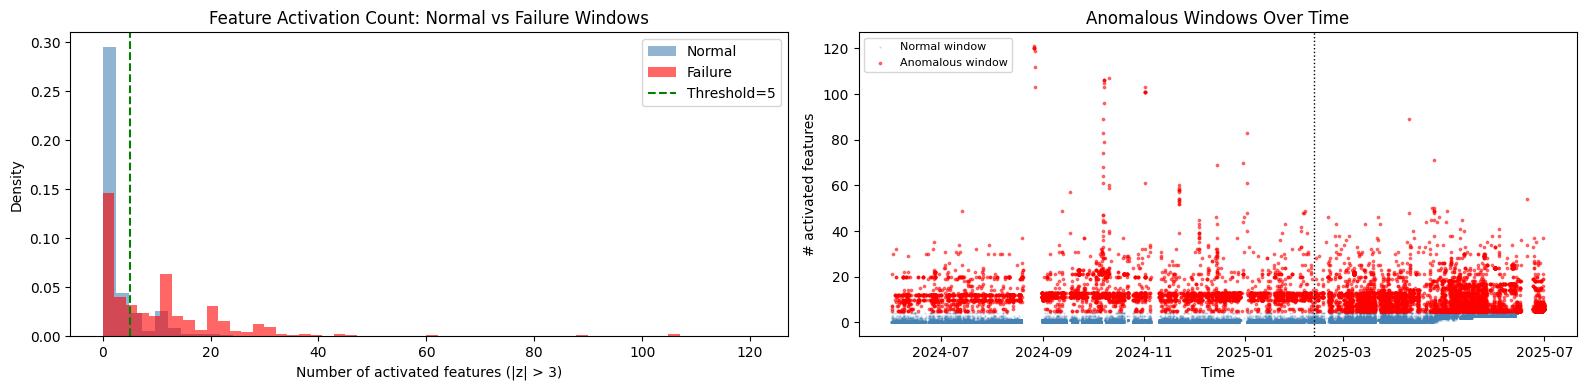

In [4]:
# Compute z-scores relative to train-normal distribution
train_normal = all_sup[(all_sup['split'] == 'train') & (all_sup['label'] == 0)]
feat_means = train_normal[feature_cols].mean()
feat_stds = train_normal[feature_cols].std()
feat_stds = feat_stds.replace(0, 1)  # avoid division by zero
del train_normal; gc.collect()

# Z-score all windows
Z_THRESH = 3.0  # a feature is "activated" if |z| > 3
zscores = (all_sup[feature_cols] - feat_means) / feat_stds
activations = (zscores.abs() > Z_THRESH).astype(int)  # binary: 1 = anomalous feature

# Count activated features per window
all_sup['n_activated'] = activations.sum(axis=1)

# A window is "anomalous" if >= 5 features are activated
MIN_ACTIVATED = 5
all_sup['is_anomalous'] = (all_sup['n_activated'] >= MIN_ACTIVATED).astype(int)

n_anom = all_sup['is_anomalous'].sum()
n_anom_fail = all_sup.loc[all_sup['is_anomalous'] == 1, 'label'].sum()
n_anom_normal = n_anom - n_anom_fail

print(f'Z-score threshold: |z| > {Z_THRESH}')
print(f'Min activated features: {MIN_ACTIVATED}')
print(f'\nAnomalous windows: {n_anom} / {len(all_sup)} ({100*n_anom/len(all_sup):.1f}%)')
print(f'  With failure label: {n_anom_fail} ({100*n_anom_fail/max(n_anom,1):.1f}%)')
print(f'  Without failure label: {n_anom_normal} ({100*n_anom_normal/max(n_anom,1):.1f}%)')
print(f'\nFor comparison:')
print(f'  Total failure windows: {all_sup["label"].sum()}')
print(f'  Failure windows that are anomalous: {n_anom_fail} ({100*n_anom_fail/max(all_sup["label"].sum(),1):.1f}%)')

# Distribution of n_activated
fig, axes = plt.subplots(1, 2, figsize=(16, 4))

ax = axes[0]
ax.hist(all_sup.loc[all_sup['label']==0, 'n_activated'], bins=50, alpha=0.6, color='steelblue', label='Normal', density=True)
ax.hist(all_sup.loc[all_sup['label']==1, 'n_activated'], bins=50, alpha=0.6, color='red', label='Failure', density=True)
ax.axvline(MIN_ACTIVATED, color='green', linestyle='--', label=f'Threshold={MIN_ACTIVATED}')
ax.set_xlabel('Number of activated features (|z| > 3)')
ax.set_ylabel('Density')
ax.set_title('Feature Activation Count: Normal vs Failure Windows')
ax.legend()

ax = axes[1]
ax.scatter(all_sup.loc[all_sup['is_anomalous']==0, 'window_end'],
           all_sup.loc[all_sup['is_anomalous']==0, 'n_activated'],
           s=0.5, alpha=0.2, c='steelblue', label='Normal window')
ax.scatter(all_sup.loc[all_sup['is_anomalous']==1, 'window_end'],
           all_sup.loc[all_sup['is_anomalous']==1, 'n_activated'],
           s=3, alpha=0.5, c='red', label='Anomalous window')
ax.axvline(SPLIT_DATE, color='black', linestyle=':', linewidth=1)
ax.set_xlabel('Time')
ax.set_ylabel('# activated features')
ax.set_title('Anomalous Windows Over Time')
ax.legend(loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()

Total windows: 64,522 | Total failure windows: 1202

z_thresh min_act  Anomalous % of all  Fail det  Precision   Recall
-----------------------------------------------------------------
     2.0       1     48,913    75.8%      1129       2.3%    93.9%
     2.0       3     40,631    63.0%      1093       2.7%    90.9%
     2.0       5     36,975    57.3%      1063       2.9%    88.4%
     2.0      10     32,634    50.6%      1012       3.1%    84.2%
     2.0      15     24,287    37.6%       929       3.8%    77.3%
     2.0      20     19,391    30.1%       869       4.5%    72.3%
     2.5       1     39,288    60.9%      1040       2.6%    86.5%
     2.5       3     25,376    39.3%       917       3.6%    76.3%
     2.5       5     21,027    32.6%       875       4.2%    72.8%
     2.5      10     15,755    24.4%       799       5.1%    66.5%
     2.5      15      6,417     9.9%       535       8.3%    44.5%
     2.5      20      4,761     7.4%       408       8.6%    33.9%
     3.0  

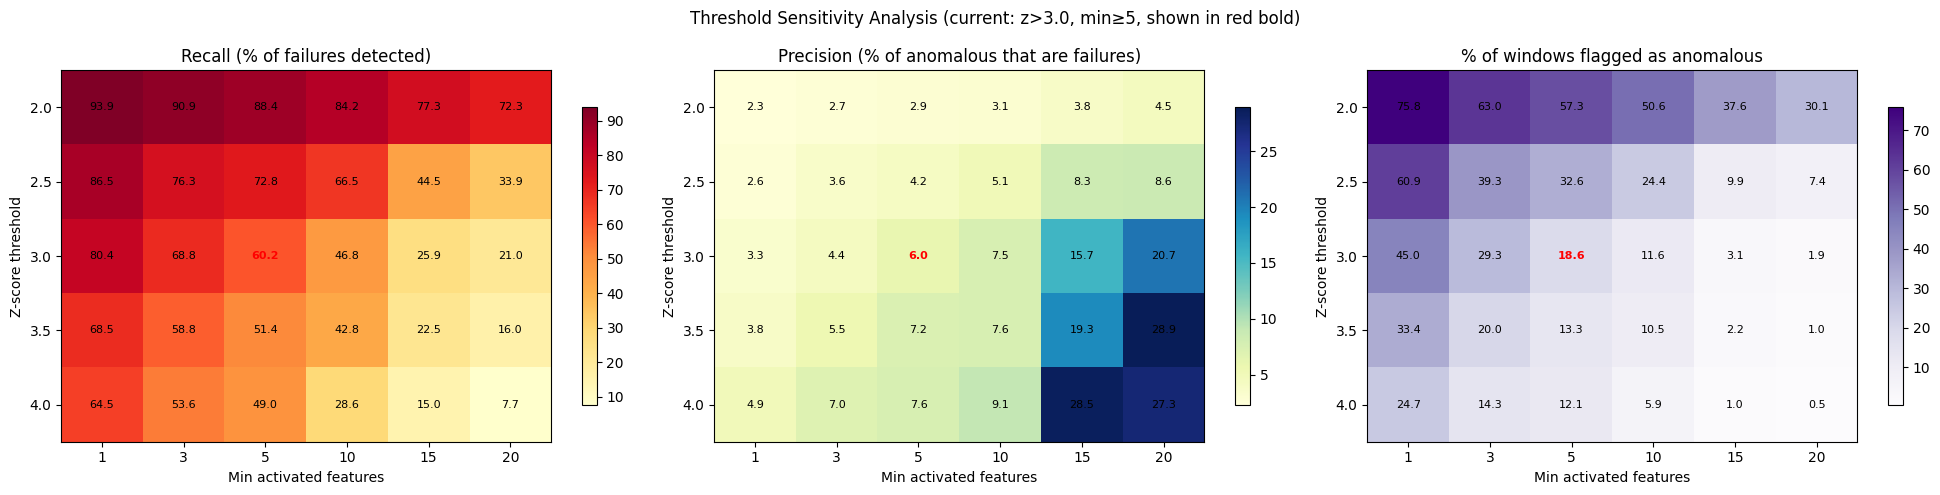


Current setting (z>3.0, min≥5): 60.2% recall, 6.0% precision
Highest recall:    z>2.0, min≥1 → 93.9% recall, 2.3% precision
Highest precision: z>3.5, min≥20 → 16.0% recall, 28.9% precision

The current thresholds balance recall and anomaly volume.


In [5]:
# ── Threshold sensitivity analysis ──
# How do results change with different z-score thresholds and min-activated-features?

z_thresholds = [2.0, 2.5, 3.0, 3.5, 4.0]
min_activated_values = [1, 3, 5, 10, 15, 20]

total_windows = len(all_sup)
total_failures = int(all_sup['label'].sum())

# Precompute activations for each z-threshold
results = []
for z in z_thresholds:
    act_z = (zscores.abs() > z).sum(axis=1)
    for m in min_activated_values:
        is_anom = act_z >= m
        n_anom = int(is_anom.sum())
        n_fail_detected = int(all_sup.loc[is_anom, 'label'].sum())
        precision = 100 * n_fail_detected / max(n_anom, 1)
        recall = 100 * n_fail_detected / max(total_failures, 1)
        results.append({
            'z_thresh': z, 'min_act': m,
            'n_anomalous': n_anom,
            'pct_anomalous': 100 * n_anom / total_windows,
            'fail_detected': n_fail_detected,
            'precision': precision,
            'recall': recall
        })

res_df = pd.DataFrame(results)

# Print summary table
print(f'Total windows: {total_windows:,} | Total failure windows: {total_failures}')
print()
print(f'{"z_thresh":>8} {"min_act":>7} {"Anomalous":>10} {"% of all":>8} {"Fail det":>9} {"Precision":>10} {"Recall":>8}')
print('-' * 65)
for _, r in res_df.iterrows():
    marker = ' ◄' if r['z_thresh'] == Z_THRESH and r['min_act'] == MIN_ACTIVATED else ''
    print(f'{r["z_thresh"]:>8.1f} {r["min_act"]:>7.0f} {r["n_anomalous"]:>10,.0f} {r["pct_anomalous"]:>7.1f}% {r["fail_detected"]:>9.0f} {r["precision"]:>9.1f}% {r["recall"]:>7.1f}%{marker}')

# Heatmaps: precision and recall across threshold combinations
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

for ax, metric, title, cmap in [
    (axes[0], 'recall', 'Recall (% of failures detected)', 'YlOrRd'),
    (axes[1], 'precision', 'Precision (% of anomalous that are failures)', 'YlGnBu'),
    (axes[2], 'pct_anomalous', '% of windows flagged as anomalous', 'Purples'),
]:
    pivot = res_df.pivot(index='z_thresh', columns='min_act', values=metric)
    im = ax.imshow(pivot.values, cmap=cmap, aspect='auto')
    ax.set_xticks(range(len(min_activated_values)))
    ax.set_xticklabels(min_activated_values)
    ax.set_yticks(range(len(z_thresholds)))
    ax.set_yticklabels(z_thresholds)
    ax.set_xlabel('Min activated features')
    ax.set_ylabel('Z-score threshold')
    ax.set_title(title)
    # Annotate cells
    for i in range(len(z_thresholds)):
        for j in range(len(min_activated_values)):
            val = pivot.values[i, j]
            # Highlight current choice
            is_current = (z_thresholds[i] == Z_THRESH and min_activated_values[j] == MIN_ACTIVATED)
            weight = 'bold' if is_current else 'normal'
            color = 'red' if is_current else 'black'
            ax.text(j, i, f'{val:.1f}', ha='center', va='center',
                    fontsize=8, fontweight=weight, color=color)
    plt.colorbar(im, ax=ax, shrink=0.8)

plt.suptitle(f'Threshold Sensitivity Analysis (current: z>{Z_THRESH}, min≥{MIN_ACTIVATED}, shown in red bold)', fontsize=12)
plt.tight_layout()
plt.show()

# Interpretation
best_recall = res_df.loc[res_df['recall'].idxmax()]
best_precision = res_df.loc[res_df['precision'].idxmax()]
current = res_df[(res_df['z_thresh'] == Z_THRESH) & (res_df['min_act'] == MIN_ACTIVATED)].iloc[0]
print(f'\nCurrent setting (z>{Z_THRESH}, min≥{MIN_ACTIVATED}): {current["recall"]:.1f}% recall, {current["precision"]:.1f}% precision')
print(f'Highest recall:    z>{best_recall["z_thresh"]}, min≥{best_recall["min_act"]:.0f} → {best_recall["recall"]:.1f}% recall, {best_recall["precision"]:.1f}% precision')
print(f'Highest precision: z>{best_precision["z_thresh"]}, min≥{best_precision["min_act"]:.0f} → {best_precision["recall"]:.1f}% recall, {best_precision["precision"]:.1f}% precision')
print(f'\nThe current thresholds balance recall and anomaly volume.')

         windows  anomaly_rate (%)  failure_rate (%)  anomaly_rate_normal_phase (%)
month                                                                              
2024-06     5142               9.0               1.4                            6.6
2024-07     5327              10.6               0.0                           10.6
2024-08     3609              13.3               0.7                            8.0
2024-09     5258              17.4               2.1                           14.9
2024-10     4171              19.3               4.9                           11.6
2024-11     4675              10.1               0.0                            9.1
2024-12     5601              13.4               1.2                           14.2
2025-01     5652              11.4               0.9                           10.9
2025-02     4710              11.5               3.2                           12.7
2025-03     5846              21.7               0.9                        

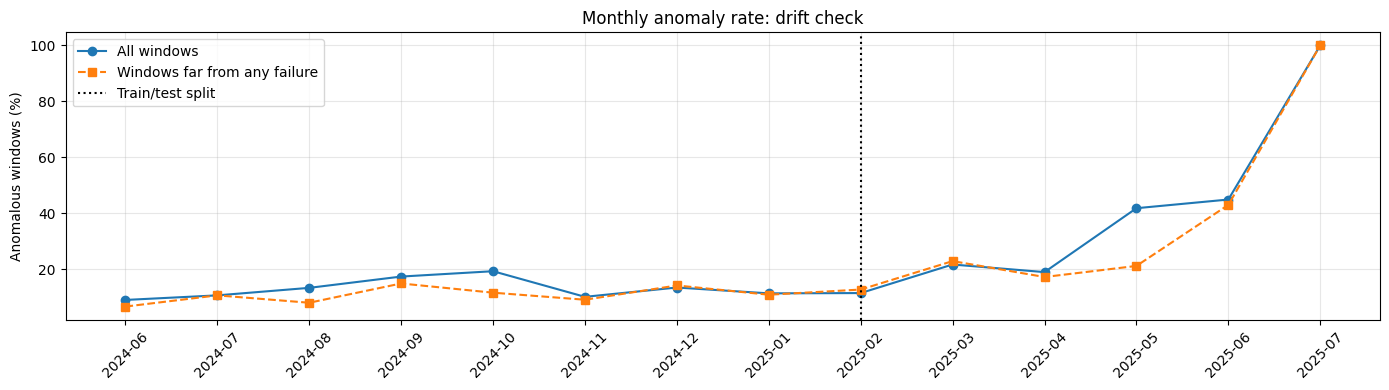

In [6]:
# ── Distribution shift check: anomaly rate per month ──
# Steiner et al. (RAMS 2026) report a baseline shift after 2025-04-17. A rising anomaly rate on
# non-failure windows means part of the test-period activations reflects drift, not degradation.
monthly = (all_sup.assign(month=all_sup['window_end'].dt.to_period('M'))
           .groupby('month')
           .agg(windows=('is_anomalous', 'size'), anomaly_rate=('is_anomalous', 'mean'),
                failure_rate=('label', 'mean')))
normal_only = all_sup[all_sup['phase'] == 'normal']
monthly['anomaly_rate_normal_phase'] = normal_only.groupby(normal_only['window_end'].dt.to_period('M'))['is_anomalous'].mean()
print((monthly * [1, 100, 100, 100]).round(1).rename(columns=lambda c: c if c == 'windows' else c + ' (%)').to_string())

tr = all_sup.loc[(all_sup.split == 'train') & (all_sup.phase == 'normal'), 'is_anomalous'].mean()
te = all_sup.loc[(all_sup.split == 'test') & (all_sup.phase == 'normal'), 'is_anomalous'].mean()
print(f'\nAnomaly rate on windows far from any failure: train {100*tr:.1f}% vs test {100*te:.1f}%')

fig, ax = plt.subplots(figsize=(14, 4))
x = monthly.index.astype(str)
ax.plot(x, 100 * monthly['anomaly_rate'], 'o-', label='All windows')
ax.plot(x, 100 * monthly['anomaly_rate_normal_phase'], 's--', label='Windows far from any failure')
ax.axvline(str(SPLIT_DATE.to_period('M')), color='black', ls=':', label='Train/test split')
ax.set_ylabel('Anomalous windows (%)')
ax.set_title('Monthly anomaly rate: drift check')
ax.legend()
ax.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 2. Feature Activation Profiles

For each anomalous window, we have a binary vector: which of the 340 features are activated (|z| > 3)?

This is the "fingerprint" of each anomaly â€” which sensors are behaving unusually.

In [7]:
# Extract activation profiles for anomalous windows only
anom_mask = all_sup['is_anomalous'] == 1
anom_orig_idx = all_sup.index[anom_mask]  # original indices into all_sup
anom_activations = activations.loc[anom_mask].reset_index(drop=True)
anom_meta = all_sup.loc[anom_mask, ['window_end', 'label', 'split', 'n_activated']].reset_index(drop=True)

# The feature clusters are FITTED on the train-period anomalous windows only, so the test period stays
# unseen for the subsystem-aware vs full-feature comparison (RQ2). The fixed clusters are then applied to
# all windows (train and test) in the analyses of section 4.
fit_mask = (anom_meta['split'] == 'train').values
anom_fit = anom_activations.loc[fit_mask]
fit_orig_idx = anom_orig_idx[fit_mask]

print(f'Anomalous windows: {len(anom_activations)} (train: {len(anom_fit)}, test: {len(anom_activations) - len(anom_fit)})')
print(f'Activation matrix shape: {anom_activations.shape}')
print(f'Clustering is fitted on the {len(anom_fit)} train-period anomalous windows')

# Which features are most commonly activated (train-period anomalous windows)?
feat_freq = anom_fit.sum().sort_values(ascending=False)
feat_freq_pct = (feat_freq / len(anom_fit) * 100).round(1)

print(f'\nTop 30 most frequently activated features:')
top30 = feat_freq.head(30)
for f, count in top30.items():
    pct = count / len(anom_fit) * 100
    print(f'  {f:55s} {count:5d} ({pct:5.1f}%)')

# Never-activated features
never_activated = (feat_freq == 0).sum()
print(f'\nFeatures never activated: {never_activated} / {len(feature_cols)}')

Anomalous windows: 12022 (train: 5351, test: 6671)
Activation matrix shape: (12022, 258)
Clustering is fitted on the 5351 train-period anomalous windows

Top 30 most frequently activated features:
  MW3_BRAKE_CYLINDER_PRESSURE_BOGIE2_max                   2213 ( 41.4%)
  MW4_LOAD_SIGNAL_min                                      1948 ( 36.4%)
  CW2_BRAKE_CYLINDER_PRESSURE_BOGIE1_min                   1865 ( 34.9%)
  CW2_BRAKE_CYLINDER_PRESSURE_BOGIE2_min                   1861 ( 34.8%)
  CW1_BRAKE_CYLINDER_PRESSURE_BOGIE1_min                   1858 ( 34.7%)
  MW1_BRAKE_CYLINDER_PRESSURE_BOGIE2_min                   1855 ( 34.7%)
  MW2_BRAKE_CYLINDER_PRESSURE_BOGIE2_min                   1853 ( 34.6%)
  CW1_BRAKE_CYLINDER_PRESSURE_BOGIE2_min                   1852 ( 34.6%)
  MW3_BRAKE_CYLINDER_PRESSURE_BOGIE1_min                   1834 ( 34.3%)
  MW1_BRAKE_CYLINDER_PRESSURE_BOGIE1_min                   1827 ( 34.1%)
  MW2_BRAKE_CYLINDER_PRESSURE_BOGIE1_min                   1820 ( 34.0%)


In [8]:
# ── Deeper look: which activated features are actually failure-relevant? ──

# For each feature: how often does it fire in failure vs normal anomalous windows?
fail_anom = anom_meta['label'] == 1
norm_anom = anom_meta['label'] == 0

baseline_rate = 100 * fail_anom.mean()
top30_feats = feat_freq.head(30).index.tolist()

print(f'{"Feature":<55} {"Total":>6} {"In Fail":>8} {"In Norm":>8} {"Fail Rate":>10}')
print('=' * 95)
for f in top30_feats:
    total = int(anom_activations[f].sum())
    in_fail = int(anom_activations.loc[fail_anom, f].sum())
    in_norm = int(anom_activations.loc[norm_anom, f].sum())
    fail_rate = 100 * in_fail / max(total, 1)
    marker = ' ***' if fail_rate > baseline_rate else ''
    print(f'{f:<55} {total:>6} {in_fail:>8} {in_norm:>8} {fail_rate:>9.1f}%{marker}')

print()
print(f'*** = failure rate > {baseline_rate:.1f}% baseline (more predictive than chance)')

Feature                                                  Total  In Fail  In Norm  Fail Rate
MW3_BRAKE_CYLINDER_PRESSURE_BOGIE2_max                    3644      265     3379       7.3% ***
MW4_LOAD_SIGNAL_min                                       3925      398     3527      10.1% ***
CW2_BRAKE_CYLINDER_PRESSURE_BOGIE1_min                    2676      117     2559       4.4%
CW2_BRAKE_CYLINDER_PRESSURE_BOGIE2_min                    2647      107     2540       4.0%
CW1_BRAKE_CYLINDER_PRESSURE_BOGIE1_min                    2649      105     2544       4.0%
MW1_BRAKE_CYLINDER_PRESSURE_BOGIE2_min                    2644      100     2544       3.8%
MW2_BRAKE_CYLINDER_PRESSURE_BOGIE2_min                    2661      112     2549       4.2%
CW1_BRAKE_CYLINDER_PRESSURE_BOGIE2_min                    2653      101     2552       3.8%
MW3_BRAKE_CYLINDER_PRESSURE_BOGIE1_min                    2628      107     2521       4.1%
MW1_BRAKE_CYLINDER_PRESSURE_BOGIE1_min                    2631      114 

In [9]:
# Group by physical sensor (strip _min/_max/_mean/_std/_flips suffix)
print()
print('─' * 60)
print('Aggregated by physical sensor (top 15):')
print('─' * 60)
sensor_info = {}
for f in feat_freq.index:
    for suf in ['_min', '_max', '_mean', '_std', '_flips']:
        if f.endswith(suf):
            sensor = f[:-len(suf)]
            if sensor not in sensor_info:
                sensor_info[sensor] = {'total': 0, 'active_feats': 0, 'all_feats': 0, 'which': []}
            sensor_info[sensor]['total'] += int(feat_freq[f])
            sensor_info[sensor]['all_feats'] += 1
            if int(feat_freq[f]) > 0:
                sensor_info[sensor]['active_feats'] += 1
                sensor_info[sensor]['which'].append(suf[1:])  # strip leading _
            break

sorted_sensors = sorted(sensor_info.items(), key=lambda x: x[1]['total'], reverse=True)
print(f'{"Sensor":<45} {"Activations":>12} {"Active/Total":>13}  Which')
print('-' * 95)
for sensor, info in sorted_sensors[:15]:
    which_str = ', '.join(info['which'])
    print(f'{sensor:<45} {info["total"]:>12} {info["active_feats"]:>6}/{info["all_feats"]:<6}  {which_str}')


────────────────────────────────────────────────────────────
Aggregated by physical sensor (top 15):
────────────────────────────────────────────────────────────
Sensor                                         Activations  Active/Total  Which
-----------------------------------------------------------------------------------------------
MW3_BRAKE_CYLINDER_PRESSURE_BOGIE2                    4027      2/3       max, min
MW1_BRAKE_CYLINDER_PRESSURE_BOGIE2                    3441      2/3       min, max
CW2_BRAKE_CYLINDER_PRESSURE_BOGIE2                    3381      2/3       min, max
MW2_BRAKE_CYLINDER_PRESSURE_BOGIE2                    3372      2/3       min, max
CW1_BRAKE_CYLINDER_PRESSURE_BOGIE2                    3365      2/3       min, max
MW3_BRAKE_CYLINDER_PRESSURE_BOGIE1                    3362      2/3       min, max
MW1_BRAKE_CYLINDER_PRESSURE_BOGIE1                    3361      2/3       min, max
MW2_BRAKE_CYLINDER_PRESSURE_BOGIE1                    3355      2/3       min, m

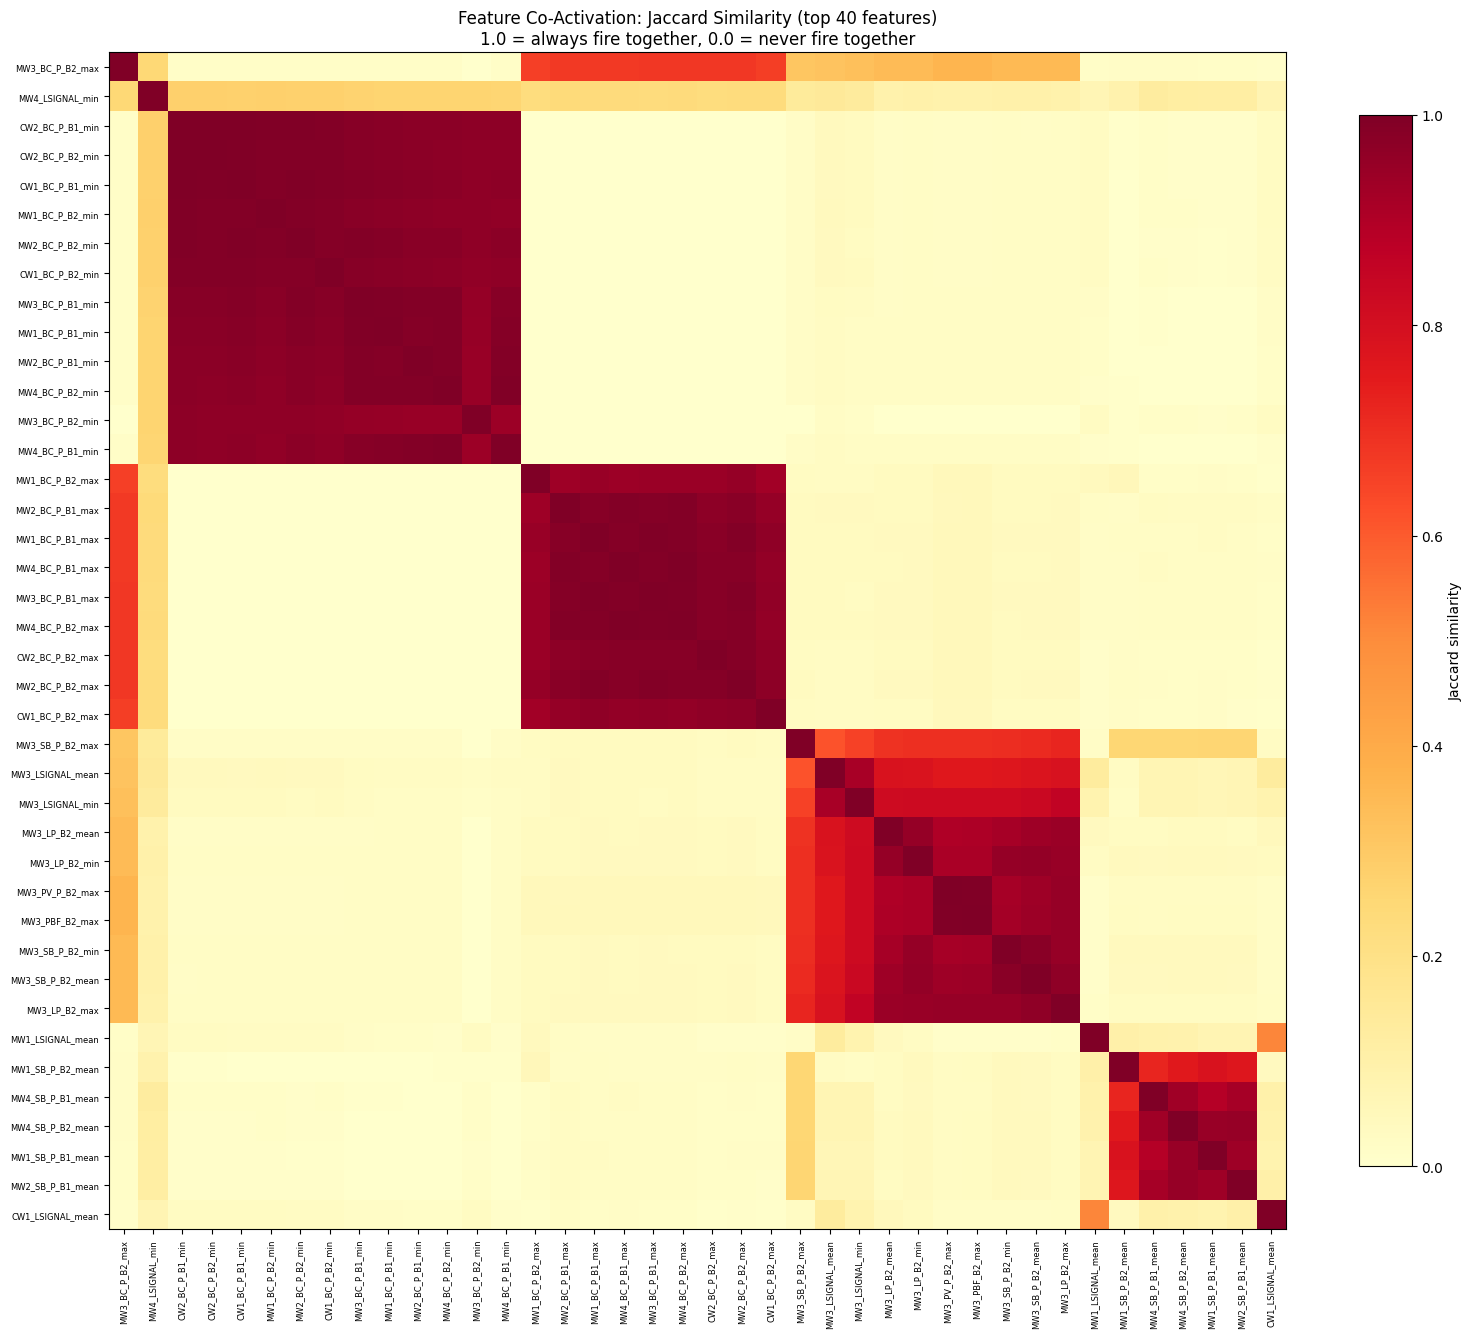

Diagonal = 1.0 (feature with itself)
Off-diagonal bright blocks = features that reliably co-activate
These blocks are what the clustering algorithm discovers automatically.


In [10]:
# ── Option A: Feature Co-Activation Matrix (Jaccard Similarity) ──
# For each pair of features: of the windows where either fires, how often do BOTH fire?
# Jaccard = |A ∩ B| / |A ∪ B|  (0 = never together, 1 = always together)

top40_feats = feat_freq.head(40).index.tolist()
act_matrix = anom_fit[top40_feats].values  # train-period anomalous windows (fitting set)
n_feats_40 = len(top40_feats)

# Compute pairwise Jaccard similarity
jaccard_sim = np.zeros((n_feats_40, n_feats_40))
for i in range(n_feats_40):
    for j in range(n_feats_40):
        intersection = (act_matrix[:, i] & act_matrix[:, j]).sum()
        union = (act_matrix[:, i] | act_matrix[:, j]).sum()
        jaccard_sim[i, j] = intersection / max(union, 1)

# Short labels for readability
short_labels = [f.replace('PRESSURE', 'P').replace('BOGIE', 'B').replace('BRAKE_CYLINDER', 'BC')
                .replace('SPRING_BRAKE', 'SB').replace('PROPORTIONAL_VALVE', 'PV')
                .replace('PNEUMATIC_BRAKING_FORCE', 'PBF').replace('LOAD_', 'L')
                .replace('MAIN_RESERVOIR', 'MR').replace('ENERGY_BRAKING_RESISTANCE', 'EBR')
                for f in top40_feats]

fig, ax = plt.subplots(figsize=(16, 14))
im = ax.imshow(jaccard_sim, cmap='YlOrRd', vmin=0, vmax=1)
ax.set_xticks(range(len(short_labels)))
ax.set_yticks(range(len(short_labels)))
ax.set_xticklabels(short_labels, rotation=90, fontsize=6)
ax.set_yticklabels(short_labels, fontsize=6)
ax.set_title('Feature Co-Activation: Jaccard Similarity (top 40 features)\n1.0 = always fire together, 0.0 = never fire together')
plt.colorbar(im, ax=ax, label='Jaccard similarity', shrink=0.8)
plt.tight_layout()
plt.show()

print(f"Diagonal = 1.0 (feature with itself)")
print(f"Off-diagonal bright blocks = features that reliably co-activate")
print(f"These blocks are what the clustering algorithm discovers automatically.")

## 3. Feature Clustering

We cluster **features** (not windows) by their co-activation patterns. Features that consistently fire together across anomalous windows are grouped into **feature clusters (FCs)**. Each FC is a data-driven group of sensors that tend to deviate together. Whether an FC corresponds to a physical subsystem or failure mode is left to expert verification.

The clustering (and its validation in 3.1 and 3.2) uses only the **train-period** anomalous windows. The test period is never used to form the clusters, so it remains an unseen evaluation set for RQ2.

In [11]:
# Filter to features that are activated in at least 1% of the train-period anomalous windows
min_freq = max(int(len(anom_fit) * 0.01), 2)
active_feats = feat_freq[feat_freq >= min_freq].index.tolist()
print(f'Features activated in >= {min_freq} windows: {len(active_feats)} / {len(feature_cols)}')


Features activated in >= 53 windows: 126 / 258


In [12]:
# ── Heuristic A: Jaccard distance on feature co-activation ──
feat_binary = anom_fit[active_feats].values  # train-period windows x features
feat_dist_jaccard = pdist(feat_binary.T, metric='jaccard')
Z_feat_a = linkage(feat_dist_jaccard, method='average')
feat_labels_a = fcluster(Z_feat_a, t=0.7, criterion='distance')

heuristic_a = {}
for f, cl in zip(active_feats, feat_labels_a):
    heuristic_a.setdefault(int(cl), []).append(f)
n_clusters_a = len(heuristic_a)

# ── Heuristic B: Correlation-based clustering ──
anom_data = all_sup.loc[fit_orig_idx, active_feats]
corr_matrix = anom_data.corr().abs()
corr_dist = 1 - corr_matrix.values
np.fill_diagonal(corr_dist, 0)
corr_dist = np.clip(corr_dist, 0, None)
corr_dist_condensed = squareform(corr_dist)
Z_feat_b = linkage(corr_dist_condensed, method='average')
feat_labels_b = fcluster(Z_feat_b, t=0.5, criterion='distance')

heuristic_b = {}
for f, cl in zip(active_feats, feat_labels_b):
    heuristic_b.setdefault(int(cl), []).append(f)
n_clusters_b = len(heuristic_b)

print(f"Heuristic A (Jaccard): {n_clusters_a} clusters")
print(f"Heuristic B (Correlation): {n_clusters_b} clusters")
print()
print("Heuristic B clusters (top 10 by size):")
for cl_id in sorted(heuristic_b.keys(), key=lambda x: len(heuristic_b[x]), reverse=True)[:10]:
    feats = heuristic_b[cl_id]
    cl_active = anom_activations[feats].any(axis=1)
    n_windows = cl_active.sum()
    n_fail = all_sup.loc[anom_orig_idx[cl_active.values], 'label'].sum()
    fail_pct = 100 * n_fail / max(n_windows, 1)
    sensors = set()
    for f in feats:
        for suffix in ['_min', '_max', '_mean', '_std', '_flips']:
            if f.endswith(suffix):
                sensors.add(f[:-len(suffix)])
                break
    print(f"  C{cl_id}: {len(feats)} features, {len(sensors)} sensors, {n_windows} windows, {fail_pct:.1f}% failure")

Heuristic A (Jaccard): 19 clusters
Heuristic B (Correlation): 13 clusters

Heuristic B clusters (top 10 by size):
  C10: 45 features, 21 sensors, 3670 windows, 11.1% failure
  C9: 22 features, 12 sensors, 7635 windows, 6.3% failure
  C4: 18 features, 18 sensors, 2172 windows, 7.7% failure
  C8: 10 features, 5 sensors, 2626 windows, 13.4% failure
  C12: 7 features, 7 sensors, 2523 windows, 7.4% failure
  C6: 6 features, 2 sensors, 537 windows, 14.7% failure
  C7: 5 features, 2 sensors, 1461 windows, 10.3% failure
  C5: 3 features, 1 sensors, 1249 windows, 2.5% failure
  C11: 3 features, 3 sensors, 767 windows, 13.2% failure
  C1: 3 features, 3 sensors, 506 windows, 6.7% failure


In [13]:
# -- All feature clusters (Heuristic A) with details --
print(f'{"FC":>4} {"Feats":>5} {"Sensors":>7} {"Windows":>7} {"Fail%":>6}  Top Features')
print('='*100)

for cl_id in sorted(heuristic_a.keys()):
    feats = heuristic_a[cl_id]
    sensors = set()
    for f in feats:
        for suf in ['_min', '_max', '_mean', '_std', '_flips']:
            if f.endswith(suf):
                sensors.add(f[:-len(suf)])
                break
    cl_active = anom_activations[feats].any(axis=1)
    n_win = cl_active.sum()
    n_fail = all_sup.loc[anom_orig_idx[cl_active.values], 'label'].sum()
    fail_pct = 100 * n_fail / max(n_win, 1)
    top3 = ', '.join([f[:42] for f in feats[:3]])
    if len(feats) > 3:
        top3 += ', ...'
    print(f'FC{cl_id:>2} {len(feats):>5} {len(sensors):>7} {n_win:>7} {fail_pct:>5.1f}%  {top3}')

# Summary
print()
print('='*60)
print(f'Total: {len(heuristic_a)} feature groups, {sum(len(v) for v in heuristic_a.values())} features')
single = sum(1 for v in heuristic_a.values() if len(v) == 1)
print(f'Single-feature groups: {single}')
print(f'Multi-feature groups: {len(heuristic_a) - single}')

  FC Feats Sensors Windows  Fail%  Top Features
FC 1    12      12    2794   4.8%  CW2_BRAKE_CYLINDER_PRESSURE_BOGIE1_min, CW2_BRAKE_CYLINDER_PRESSURE_BOGIE2_min, CW1_BRAKE_CYLINDER_PRESSURE_BOGIE1_min, ...
FC 2     1       1    3925  10.1%  MW4_LOAD_SIGNAL_min
FC 3     4       4     679  10.6%  CW1_SPRING_BRAKE_ACTIVE_BOGIE2_flips, CW2_SPRING_BRAKE_ACTIVE_BOGIE2_flips, CW1_SPRING_BRAKE_ACTIVE_BOGIE1_flips, ...
FC 4     1       1     490   7.8%  CW1_COMPRESSOR_RUNNING_flips
FC 5     1       1     344  15.4%  CW2_COMPRESSOR_RUNNING_flips
FC 6    19      10    1166  22.0%  MW1_SPRING_BRAKE_PRESSURE_BOGIE2_mean, MW4_SPRING_BRAKE_PRESSURE_BOGIE1_mean, MW4_SPRING_BRAKE_PRESSURE_BOGIE2_mean, ...
FC 7     2       2     134  62.7%  CW1_SPRING_BRAKE_PRESSURE_BOGIE2_min, CW1_LOAD_PRESSURE_BOGIE2_max
FC 8     7       7     271  33.9%  MW2_SPRING_BRAKE_PRESSURE_BOGIE1_min, MW4_SPRING_BRAKE_PRESSURE_BOGIE1_min, MW4_SPRING_BRAKE_PRESSURE_BOGIE2_min, ...
FC 9     4       4     799  12.6%  MW1_PNEUMAT

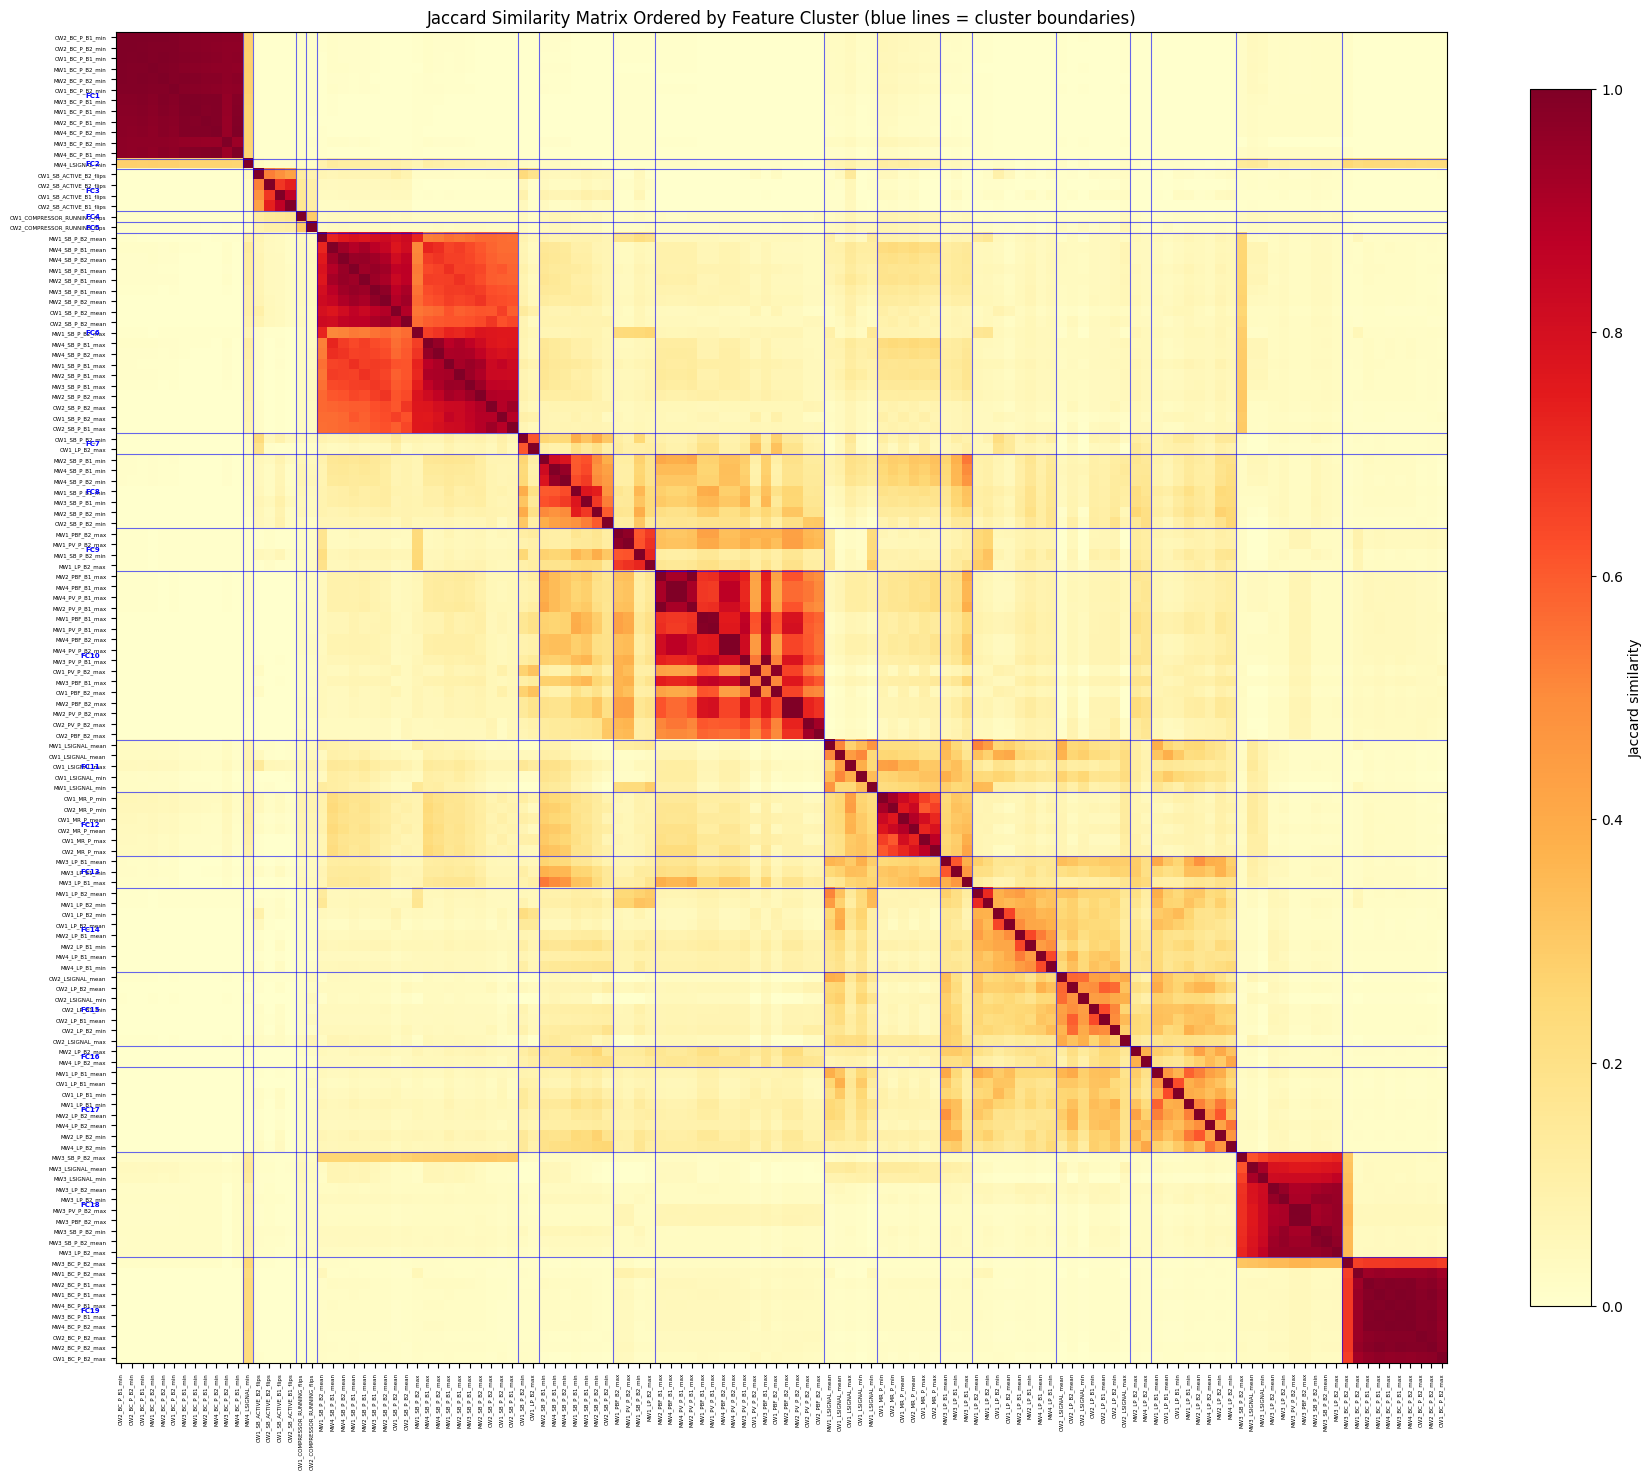

Total features shown: 126
Bright blocks along the diagonal = features within the same cluster co-activate.
Off-diagonal bright spots = clusters that tend to fire together.


In [14]:
# ── Option C: Clustered Co-Activation Heatmap (Jaccard Similarity) ──
# Same Jaccard similarity but reordered by feature cluster assignment
# This reveals the block-diagonal structure that clustering discovered

# Get all active features ordered by cluster
fc_order = []
fc_boundaries = []
pos = 0
for fc in sorted(heuristic_a.keys()):
    feats_active = [f for f in heuristic_a[fc] if f in active_feats]
    if feats_active:
        fc_order.extend(feats_active)
        fc_boundaries.append(pos)
        pos += len(feats_active)

# Compute Jaccard similarity in cluster order
act_ordered = anom_fit[fc_order].values
n_f = act_ordered.shape[0]
n_cols = len(fc_order)

jaccard_ordered = np.zeros((n_cols, n_cols))
for i in range(n_cols):
    for j in range(i, n_cols):
        intersection = (act_ordered[:, i] & act_ordered[:, j]).sum()
        union = (act_ordered[:, i] | act_ordered[:, j]).sum()
        val = intersection / max(union, 1)
        jaccard_ordered[i, j] = val
        jaccard_ordered[j, i] = val

# Short labels
short = [f.replace('PRESSURE', 'P').replace('BOGIE', 'B').replace('BRAKE_CYLINDER', 'BC')
         .replace('SPRING_BRAKE', 'SB').replace('PROPORTIONAL_VALVE', 'PV')
         .replace('PNEUMATIC_BRAKING_FORCE', 'PBF').replace('LOAD_', 'L')
         .replace('MAIN_RESERVOIR', 'MR').replace('ENERGY_BRAKING_RESISTANCE', 'EBR')
         for f in fc_order]

fig, ax = plt.subplots(figsize=(18, 16))
im = ax.imshow(jaccard_ordered, cmap='YlOrRd', vmin=0, vmax=1)

# Draw cluster boundary lines
for b in fc_boundaries[1:]:
    ax.axhline(b - 0.5, color='blue', linewidth=0.8, alpha=0.6)
    ax.axvline(b - 0.5, color='blue', linewidth=0.8, alpha=0.6)

# Label clusters on the side
fc_idx = 0
for fc in sorted(heuristic_a.keys()):
    feats_active = [f for f in heuristic_a[fc] if f in active_feats]
    if feats_active:
        mid = fc_boundaries[fc_idx] + len(feats_active) / 2 - 0.5
        ax.text(-2, mid, f'FC{fc}', fontsize=5, ha='right', va='center', color='blue', fontweight='bold')
        fc_idx += 1

ax.set_xticks(range(len(short)))
ax.set_yticks(range(len(short)))
ax.set_xticklabels(short, rotation=90, fontsize=4)
ax.set_yticklabels(short, fontsize=4)
ax.set_title('Jaccard Similarity Matrix Ordered by Feature Cluster (blue lines = cluster boundaries)')
plt.colorbar(im, ax=ax, label='Jaccard similarity', shrink=0.8)
plt.tight_layout()
plt.show()

print(f"Total features shown: {len(fc_order)}")
print("Bright blocks along the diagonal = features within the same cluster co-activate.")
print("Off-diagonal bright spots = clusters that tend to fire together.")

In [15]:
# ── Same-sensor redundancy analysis ──
# Supervisor feedback: if min/mean/max of same sensor all fire together, are they redundant?
# Answer: Yes, same-sensor aggregations are correlated by construction.
# The REAL clustering signal is cross-sensor co-activation.

# Classify each cluster
print("Feature vs Sensor redundancy analysis:")
print("="*90)
print(f"{'FC':>4} {'Feats':>5} {'Sensors':>7} {'Type':<25} {'Redundancy':>10}")
print("-"*90)

single_sensor_clusters = 0
multi_sensor_clusters = 0
total_redundant_feats = 0

for cl_id in sorted(heuristic_a.keys()):
    feats = heuristic_a[cl_id]
    sensors = set()
    for f in feats:
        for suf in ['_min', '_max', '_mean', '_std', '_flips']:
            if f.endswith(suf):
                sensors.add(f[:-len(suf)])
                break
    
    n_feats = len(feats)
    n_sensors = len(sensors)
    
    if n_feats == 1:
        ctype = "single feature"
        redundancy = "-"
    elif n_sensors == 1:
        ctype = "same-sensor aggregations"
        single_sensor_clusters += 1
        redundancy = f"{n_feats - 1} redundant"
        total_redundant_feats += n_feats - 1
    elif n_feats == n_sensors:
        ctype = "cross-sensor (no redundancy)"
        multi_sensor_clusters += 1
        redundancy = "0"
    else:
        ctype = "mixed (cross-sensor + agg)"
        multi_sensor_clusters += 1
        redundancy = f"{n_feats - n_sensors} redundant"
        total_redundant_feats += n_feats - n_sensors
    
    print(f"FC{cl_id:>2} {n_feats:>5} {n_sensors:>7} {ctype:<25} {redundancy:>10}")

print()
print("="*60)
print(f"Single-sensor clusters (pure aggregation redundancy): {single_sensor_clusters}")
print(f"Multi-sensor clusters (genuine cross-sensor patterns): {multi_sensor_clusters}")
print(f"Single-feature clusters: {sum(1 for v in heuristic_a.values() if len(v) == 1)}")
print(f"Total features: {sum(len(v) for v in heuristic_a.values())}")
print(f"Total unique sensors: {len(set(s for feats in heuristic_a.values() for f in feats for suf in ['_min','_max','_mean','_std','_flips'] if f.endswith(suf) for s in [f[:-len(suf)]]))}")
print(f"Redundant features (same-sensor duplicates): {total_redundant_feats}")
print()
print("Interpretation:")
print("Same-sensor aggregations (min/mean/max) co-activating is expected and trivial.")
print("The key finding is CROSS-SENSOR co-activation: sensors from different physical")
print("locations firing together reveals shared degradation mechanisms.")
print(f"At the sensor level, the {len(heuristic_a)} FCs collapse to fewer independent groups.")

Feature vs Sensor redundancy analysis:
  FC Feats Sensors Type                      Redundancy
------------------------------------------------------------------------------------------
FC 1    12      12 cross-sensor (no redundancy)          0
FC 2     1       1 single feature                     -
FC 3     4       4 cross-sensor (no redundancy)          0
FC 4     1       1 single feature                     -
FC 5     1       1 single feature                     -
FC 6    19      10 mixed (cross-sensor + agg) 9 redundant
FC 7     2       2 cross-sensor (no redundancy)          0
FC 8     7       7 cross-sensor (no redundancy)          0
FC 9     4       4 cross-sensor (no redundancy)          0
FC10    16      16 cross-sensor (no redundancy)          0
FC11     5       2 mixed (cross-sensor + agg) 3 redundant
FC12     6       2 mixed (cross-sensor + agg) 4 redundant
FC13     3       1 same-sensor aggregations  2 redundant
FC14     8       4 mixed (cross-sensor + agg) 4 redundant
FC1

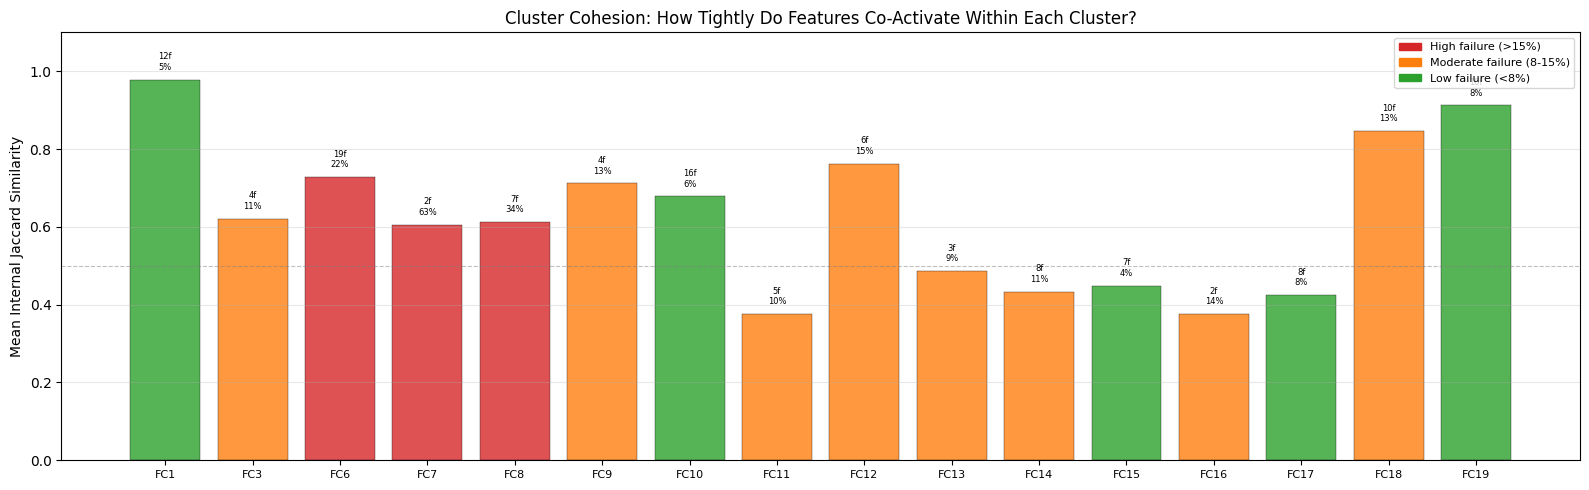

Multi-feature clusters: 16
Mean cohesion: 0.625
Clusters with cohesion > 0.5: 10
Clusters with cohesion > 0.3: 16

Annotation: Nf = number of features, % = failure rate


In [16]:
# ── Cluster Cohesion: Average Internal Jaccard Similarity per FC ──
# For each cluster with >= 2 features, compute the mean pairwise Jaccard similarity

fc_ids_all = sorted(heuristic_a.keys())
fc_labels_plot = []
fc_cohesion = []
fc_sizes = []
fc_fail_pcts = []

for fc in fc_ids_all:
    feats = [f for f in heuristic_a[fc] if f in active_feats]
    if len(feats) < 2:
        continue
    
    act_sub = anom_fit[feats].values
    n = len(feats)
    jac_vals = []
    for i in range(n):
        for j in range(i + 1, n):
            inter = (act_sub[:, i] & act_sub[:, j]).sum()
            union = (act_sub[:, i] | act_sub[:, j]).sum()
            jac_vals.append(inter / max(union, 1))
    
    cl_act = anom_activations[feats].any(axis=1)
    n_win = cl_act.sum()
    n_fail = int(anom_meta.loc[cl_act, 'label'].sum())
    
    fc_labels_plot.append(f'FC{fc}')
    fc_cohesion.append(np.mean(jac_vals))
    fc_sizes.append(len(feats))
    fc_fail_pcts.append(100 * n_fail / max(n_win, 1))

# Plot
fig, ax = plt.subplots(figsize=(16, 5))
x = np.arange(len(fc_labels_plot))
colors = ['#d62728' if fp > 15 else '#ff7f0e' if fp > 8 else '#2ca02c' for fp in fc_fail_pcts]
bars = ax.bar(x, fc_cohesion, color=colors, alpha=0.8, edgecolor='black', linewidth=0.3)

# Annotate with size and failure %
for i, (coh, sz, fp) in enumerate(zip(fc_cohesion, fc_sizes, fc_fail_pcts)):
    ax.text(i, coh + 0.02, f'{sz}f\n{fp:.0f}%', ha='center', va='bottom', fontsize=6)

ax.set_xticks(x)
ax.set_xticklabels(fc_labels_plot, fontsize=8)
ax.set_ylabel('Mean Internal Jaccard Similarity')
ax.set_title('Cluster Cohesion: How Tightly Do Features Co-Activate Within Each Cluster?')
ax.set_ylim(0, 1.1)
ax.axhline(0.5, color='gray', linestyle='--', linewidth=0.8, alpha=0.5, label='0.5 threshold')
ax.grid(axis='y', alpha=0.3)

# Legend for colors
from matplotlib.patches import Patch
legend_patches = [
    Patch(color='#d62728', label='High failure (>15%)'),
    Patch(color='#ff7f0e', label='Moderate failure (8-15%)'),
    Patch(color='#2ca02c', label='Low failure (<8%)')
]
ax.legend(handles=legend_patches, loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()

# Summary stats
print(f'Multi-feature clusters: {len(fc_cohesion)}')
print(f'Mean cohesion: {np.mean(fc_cohesion):.3f}')
print(f'Clusters with cohesion > 0.5: {sum(1 for c in fc_cohesion if c > 0.5)}')
print(f'Clusters with cohesion > 0.3: {sum(1 for c in fc_cohesion if c > 0.3)}')
print()
print('Annotation: Nf = number of features, % = failure rate')

#### Sensor location per FC (neutral structural descriptor)

The train has two control chains: CW1 governs MW1/MW2 (side A) and CW2 governs MW3/MW4 (side B) (MetroAT, CIRP CMS 2025; Helm 2025, p68). Brake-actuation signals within one chain correlate at |r| ≥ 0.99 because they are actuated together, so **high cohesion can partly reflect synchronous actuation rather than shared degradation**. The table describes *where* an FC's sensors are located. It is not a subsystem label; that assignment is left to the experts.

In [17]:
def sensor_location(f):
    car = f.split('_')[0]
    side = 'A' if car in ('CW1', 'MW1', 'MW2') else 'B' if car in ('CW2', 'MW3', 'MW4') else '-'
    bogie = 'B1' if 'BOGIE1' in f else 'B2' if 'BOGIE2' in f else '-'
    base = f.split('_', 1)[1] if car[:2] in ('CW', 'MW') else f
    for tok in ('_BOGIE1', '_BOGIE2'):
        base = base.replace(tok, '')
    base = base.rsplit('_', 1)[0]
    return car, side, bogie, base


loc_rows = []
for fc in sorted(heuristic_a.keys()):
    info = [sensor_location(f) for f in heuristic_a[fc]]
    cars = sorted({c for c, _, _, _ in info})
    sides = [s for _, s, _, _ in info]
    loc_rows.append({
        'FC': f'FC{fc}', 'n_features': len(info),
        'cars': ', '.join(cars),
        'side_A_share': round(sides.count('A') / len(sides), 2),
        'side_B_share': round(sides.count('B') / len(sides), 2),
        'bogies': ', '.join(sorted({b for _, _, b, _ in info if b != '-'})) or '-',
        'n_signal_types': len({t for _, _, _, t in info}),
        'signal_types': ', '.join(sorted({t for _, _, _, t in info})),
    })
fc_location = pd.DataFrame(loc_rows)
print(fc_location.to_string(index=False))
one_side = ((fc_location.side_A_share == 1) | (fc_location.side_B_share == 1)).sum()
single_type = (fc_location.n_signal_types == 1).sum()
print(f'\nFCs whose sensors all sit on one control chain: {one_side}/{len(fc_location)}')
print(f'FCs made of a single signal type (e.g. only one pressure type): {single_type}/{len(fc_location)}')

  FC  n_features                         cars  side_A_share  side_B_share bogies  n_signal_types                                                                                            signal_types
 FC1          12 CW1, CW2, MW1, MW2, MW3, MW4          0.50          0.50 B1, B2               1                                                                                 BRAKE_CYLINDER_PRESSURE
 FC2           1                          MW4          0.00          1.00      -               1                                                                                             LOAD_SIGNAL
 FC3           4                     CW1, CW2          0.50          0.50 B1, B2               1                                                                                     SPRING_BRAKE_ACTIVE
 FC4           1                          CW1          1.00          0.00      -               1                                                                                      COMPRESSOR_RUN

### 3.1 Heuristic Comparison: Jaccard vs Correlation Clustering

To validate robustness, we compare two independent clustering approaches on the same features:
- **Heuristic A (Jaccard):** clusters features by binary co-activation similarity
- **Heuristic B (Correlation):** clusters features by absolute Pearson correlation on continuous values

If both produce similar groupings, the discovered structure is robust and not an artifact of the distance metric.

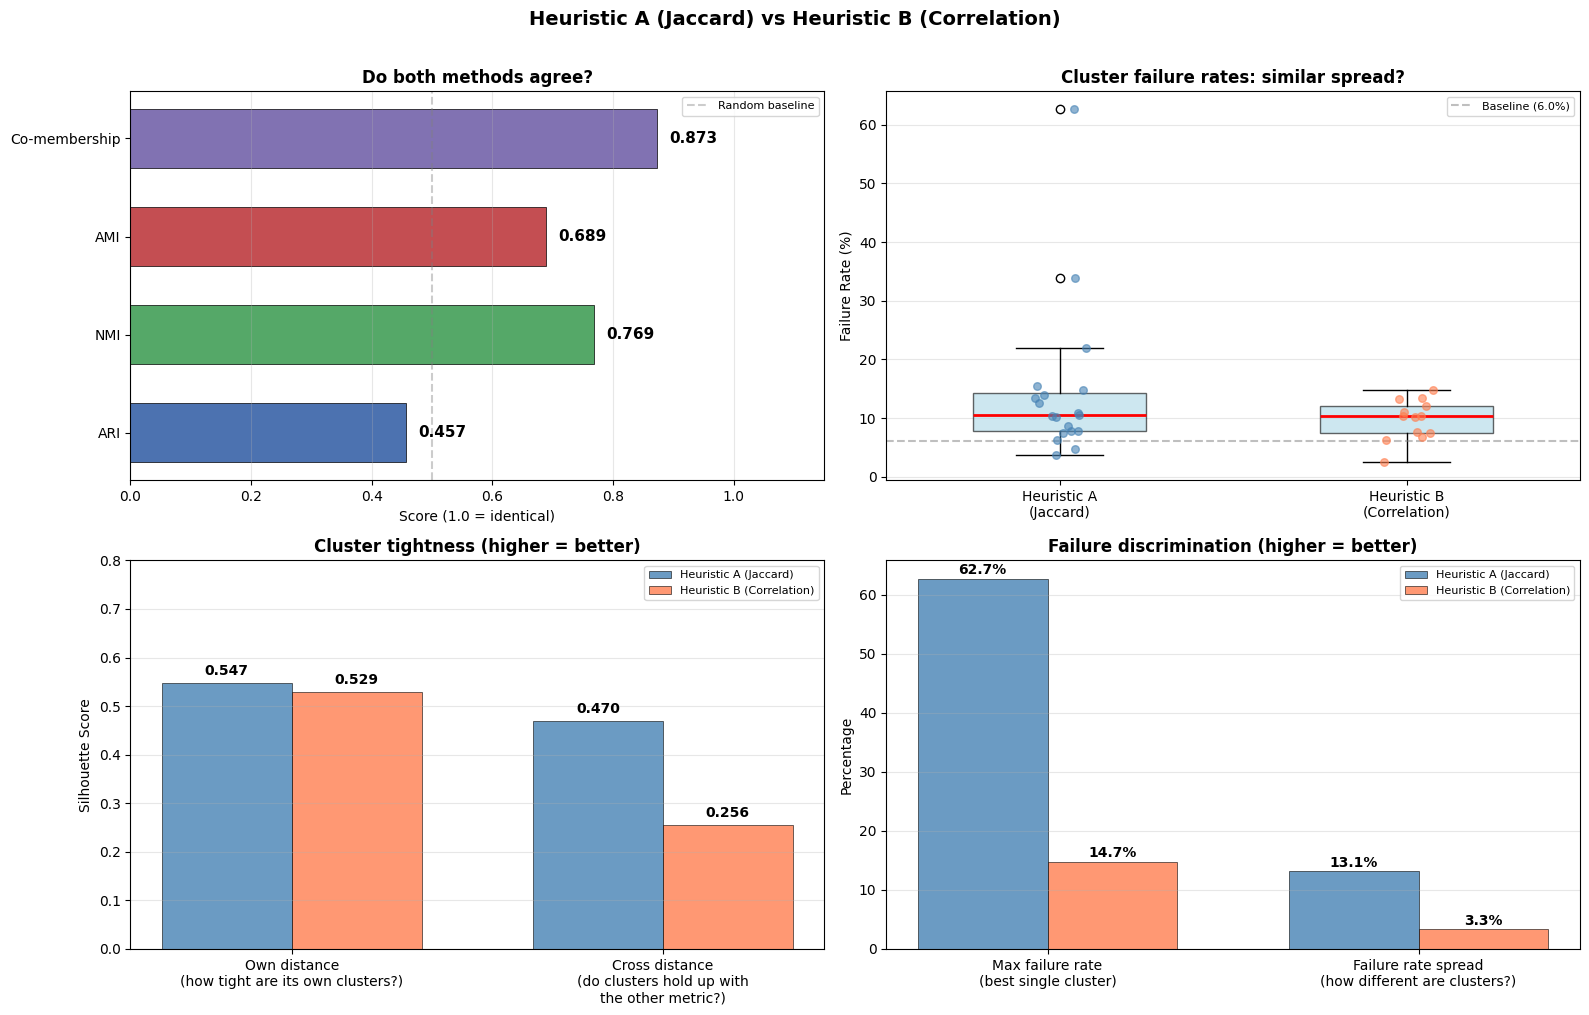

STATISTICAL COMPARISON: HEURISTIC A vs HEURISTIC B

Metric                                     Heuristic A   Heuristic B
........................................     (Jaccard) (Correlation)
----------------------------------------------------------------------
Number of clusters                                  19            13
Mean cluster size                                  6.6           9.7
Size entropy (lower=more decisive)               2.672         1.995
Silhouette (own distance)                        0.547         0.529
Silhouette (cross distance)                      0.470         0.256
Max failure rate (%)                              62.7          14.7
Failure rate range (%)                            59.0          12.2
Failure rate spread (std)                        13.14          3.29

--- Agreement Between A and B ---
Adjusted Rand Index (ARI)                        0.457
Normalized Mutual Information (NMI)              0.769
Adjusted Mutual Information (AMI)         

In [18]:
# ── Numerical comparison of Heuristic A vs Heuristic B ──
from sklearn.metrics import (adjusted_rand_score, normalized_mutual_info_score,
                             adjusted_mutual_info_score, silhouette_score as sil_score)
from scipy.stats import entropy as sp_entropy

ari = adjusted_rand_score(feat_labels_a, feat_labels_b)
nmi = normalized_mutual_info_score(feat_labels_a, feat_labels_b)
ami = adjusted_mutual_info_score(feat_labels_a, feat_labels_b)

# Co-membership agreement
def co_membership_agreement(la, lb):
    n = len(la)
    agree = sum(1 for i in range(n) for j in range(i+1, n)
                if (la[i] == la[j]) == (lb[i] == lb[j]))
    return agree / (n * (n - 1) / 2)

co_agree = co_membership_agreement(feat_labels_a, feat_labels_b)

# Silhouette scores
dist_a_sq = squareform(feat_dist_jaccard)
dist_b_sq = 1 - all_sup.loc[fit_orig_idx, active_feats].corr().abs().values
np.fill_diagonal(dist_b_sq, 0); dist_b_sq = np.clip(dist_b_sq, 0, None)

sil_a = sil_score(dist_a_sq, feat_labels_a, metric='precomputed')
sil_b = sil_score(dist_b_sq, feat_labels_b, metric='precomputed')
sil_a_x = sil_score(dist_b_sq, feat_labels_a, metric='precomputed')
sil_b_x = sil_score(dist_a_sq, feat_labels_b, metric='precomputed')

# Failure rate per cluster for both heuristics
def cluster_failure_rates(heur_dict):
    rates = []
    for cl_id in sorted(heur_dict.keys()):
        feats = heur_dict[cl_id]
        cl_active = anom_activations[feats].any(axis=1)
        n_w = cl_active.sum()
        if n_w == 0: continue
        n_f = all_sup.loc[anom_orig_idx[cl_active.values], 'label'].sum()
        rates.append(100 * n_f / n_w)
    return rates

fr_a = cluster_failure_rates(heuristic_a)
fr_b = cluster_failure_rates(heuristic_b)

# Failure discrimination
def failure_discrimination(rates):
    fr = np.array(rates)
    wstd = np.std(fr)
    return float(wstd), float(fr.max() - fr.min()), float(fr.max())

spread_a, range_a, max_a = failure_discrimination(fr_a)
spread_b, range_b, max_b = failure_discrimination(fr_b)

# Size entropy
sizes_a = np.array([np.sum(feat_labels_a == c) for c in set(feat_labels_a)])
sizes_b = np.array([np.sum(feat_labels_b == c) for c in set(feat_labels_b)])
ent_a = sp_entropy(sizes_a / sizes_a.sum())
ent_b = sp_entropy(sizes_b / sizes_b.sum())

BASELINE_FAIL_PCT = 100 * all_sup.loc[anom_orig_idx, 'label'].mean()

# ── 2x2 layout: each metric gets its own subplot with proper scale ──
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Panel 1 (top-left): Agreement — how similar are the two methods?
ax = axes[0, 0]
metrics = ['ARI', 'NMI', 'AMI', 'Co-membership']
values = [ari, nmi, ami, co_agree]
colors = ['#4c72b0', '#55a868', '#c44e52', '#8172b2']
bars = ax.barh(metrics, values, color=colors, edgecolor='black', linewidth=0.5, height=0.6)
for bar, v in zip(bars, values):
    ax.text(v + 0.02, bar.get_y() + bar.get_height()/2,
            f'{v:.3f}', ha='left', va='center', fontsize=11, fontweight='bold')
ax.set_xlim(0, 1.15)
ax.set_xlabel('Score (1.0 = identical)')
ax.set_title('Do both methods agree?', fontsize=12, fontweight='bold')
ax.axvline(0.5, color='grey', ls='--', alpha=0.4, label='Random baseline')
ax.legend(fontsize=8)
ax.grid(axis='x', alpha=0.3)

# Panel 2 (top-right): Failure rate distribution
ax = axes[0, 1]
ax.boxplot([fr_a, fr_b], labels=['Heuristic A\n(Jaccard)', 'Heuristic B\n(Correlation)'],
           widths=0.5, patch_artist=True,
           boxprops=dict(facecolor='lightblue', alpha=0.6),
           medianprops=dict(color='red', linewidth=2))
for i, (rates, color) in enumerate([(fr_a, 'steelblue'), (fr_b, 'coral')]):
    jitter = np.random.default_rng(42).uniform(-0.08, 0.08, len(rates))
    ax.scatter([i+1]*len(rates) + jitter, rates, color=color, alpha=0.6, s=30, zorder=5)
ax.axhline(BASELINE_FAIL_PCT, color='grey', ls='--', alpha=0.5, label=f'Baseline ({BASELINE_FAIL_PCT:.1f}%)')
ax.set_ylabel('Failure Rate (%)')
ax.set_title('Cluster failure rates: similar spread?', fontsize=12, fontweight='bold')
ax.legend(fontsize=8)
ax.grid(axis='y', alpha=0.3)

# Panel 3 (bottom-left): Silhouette — cluster tightness (same 0-1 scale)
ax = axes[1, 0]
x = np.arange(2)
w = 0.35
b1 = ax.bar(x - w/2, [sil_a, sil_a_x], w, label='Heuristic A (Jaccard)',
            color='steelblue', alpha=0.8, edgecolor='black', linewidth=0.5)
b2 = ax.bar(x + w/2, [sil_b, sil_b_x], w, label='Heuristic B (Correlation)',
            color='coral', alpha=0.8, edgecolor='black', linewidth=0.5)
for bars_g in [b1, b2]:
    for bar in bars_g:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.01,
                f'{h:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(['Own distance\n(how tight are its own clusters?)',
                     'Cross distance\n(do clusters hold up with\nthe other metric?)'])
ax.set_ylim(0, 0.8)
ax.set_ylabel('Silhouette Score')
ax.set_title('Cluster tightness (higher = better)', fontsize=12, fontweight='bold')
ax.legend(fontsize=8)
ax.grid(axis='y', alpha=0.3)

# Panel 4 (bottom-right): Failure discrimination (same % scale)
ax = axes[1, 1]
x = np.arange(2)
b1 = ax.bar(x - w/2, [max_a, spread_a], w, label='Heuristic A (Jaccard)',
            color='steelblue', alpha=0.8, edgecolor='black', linewidth=0.5)
b2 = ax.bar(x + w/2, [max_b, spread_b], w, label='Heuristic B (Correlation)',
            color='coral', alpha=0.8, edgecolor='black', linewidth=0.5)
for bars_g in [b1, b2]:
    for bar in bars_g:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.3,
                f'{h:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(['Max failure rate\n(best single cluster)',
                     'Failure rate spread\n(how different are clusters?)'])
ax.set_ylabel('Percentage')
ax.set_title('Failure discrimination (higher = better)', fontsize=12, fontweight='bold')
ax.legend(fontsize=8)
ax.grid(axis='y', alpha=0.3)

plt.suptitle('Heuristic A (Jaccard) vs Heuristic B (Correlation)', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'nb04_artifacts', 'heuristic_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()

# Print summary table
print('='*70)
print('STATISTICAL COMPARISON: HEURISTIC A vs HEURISTIC B')
print('='*70)
print()
print(f'{"Metric":<40} {"Heuristic A":>13} {"Heuristic B":>13}')
print(f'{"":.<40} {"(Jaccard)":>13} {"(Correlation)":>13}')
print('-'*70)
print(f'{"Number of clusters":<40} {n_clusters_a:>13} {n_clusters_b:>13}')
print(f'{"Mean cluster size":<40} {len(active_feats)/n_clusters_a:>13.1f} {len(active_feats)/n_clusters_b:>13.1f}')
print(f'{"Size entropy (lower=more decisive)":<40} {ent_a:>13.3f} {ent_b:>13.3f}')
print(f'{"Silhouette (own distance)":<40} {sil_a:>13.3f} {sil_b:>13.3f}')
print(f'{"Silhouette (cross distance)":<40} {sil_a_x:>13.3f} {sil_b_x:>13.3f}')
print(f'{"Max failure rate (%)":<40} {max_a:>13.1f} {max_b:>13.1f}')
print(f'{"Failure rate range (%)":<40} {range_a:>13.1f} {range_b:>13.1f}')
print(f'{"Failure rate spread (std)":<40} {spread_a:>13.2f} {spread_b:>13.2f}')
print()
print('--- Agreement Between A and B ---')
print(f'{"Adjusted Rand Index (ARI)":<40} {ari:>13.3f}')
print(f'{"Normalized Mutual Information (NMI)":<40} {nmi:>13.3f}')
print(f'{"Adjusted Mutual Information (AMI)":<40} {ami:>13.3f}')
print(f'{"Pairwise co-membership agreement":<40} {co_agree:>13.3f}')
print()
sil_winner = 'A' if sil_a > sil_b else 'B'
spread_winner = 'A' if spread_a > spread_b else 'B'
print(f'Heuristic {sil_winner} has better internal cohesion (silhouette {max(sil_a,sil_b):.3f} vs {min(sil_a,sil_b):.3f})')
print(f'Heuristic {spread_winner} better separates failure-prone from benign clusters (spread {max(spread_a,spread_b):.2f} vs {min(spread_a,spread_b):.2f})')
print(f'Both methods agree on {co_agree*100:.1f}% of feature pairings')
strength = 'strong' if ari > 0.6 else 'moderate' if ari > 0.3 else 'weak'
print(f'ARI={ari:.3f}, NMI={nmi:.3f} -> {strength} agreement')

### 3.2 Binary vs Continuous Validation

The key question: **does reducing continuous sensor values to binary (0/1) lose important information?**

For each feature group discovered by binary clustering (Heuristic A), we compute:
- **Binary cohesion:** mean Jaccard similarity within the group (based on 0/1 co-activation)
- **Continuous correlation:** mean absolute Pearson correlation within the group (based on actual values)

If binary cohesion and continuous correlation are strongly correlated across all groups, then the binary simplification preserves the numerical structure of the data.

Do binary-derived groups (Heuristic A) also have high continuous correlation?
Cluster    Features  Binary Cohesion  Continuous Corr   Match?
--------------------------------------------------------------------------------
A-C1             12           0.979           0.986      Yes
A-C3              4           0.621           0.633      Yes
A-C6             19           0.728           0.856      Yes
A-C7              2           0.606           0.440      Yes
A-C8              7           0.612           0.954      Yes
A-C9              4           0.712           0.382      Yes
A-C10            16           0.678           0.911      Yes
A-C11             5           0.376           0.658      Yes
A-C12             6           0.763           0.857      Yes
A-C13             3           0.486           0.776      Yes
A-C14             8           0.434           0.716      Yes
A-C15             7           0.449           0.537      Yes
A-C16             2           0.376           

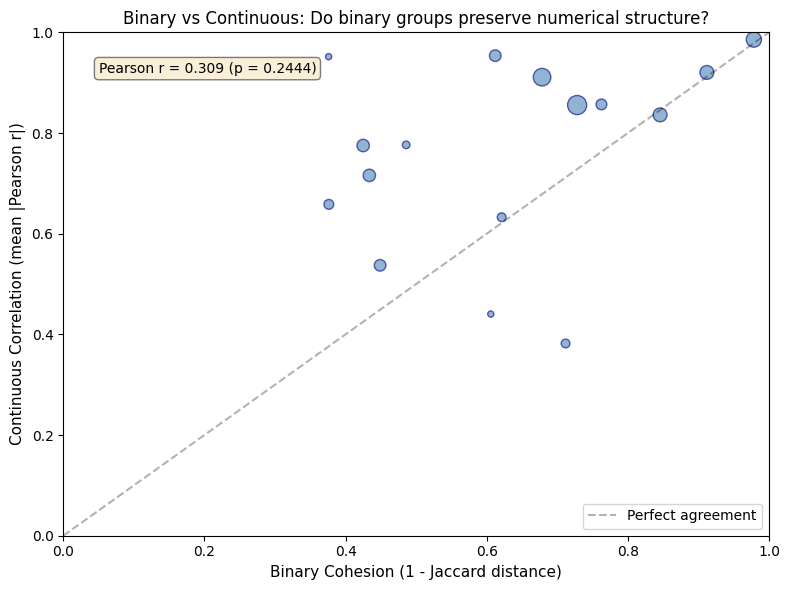


Correlation between binary cohesion and continuous correlation: r = 0.309, p = 0.2444
Conclusion: Moderate correlation suggests that binary activation
patterns capture the same sensor relationships as continuous values.


In [19]:
# ── Numerical evidence: binary vs continuous produce the same groups ──
# For each Heuristic A cluster, show average internal correlation (continuous)
# High correlation within binary-derived groups = binary captures continuous structure

print("Do binary-derived groups (Heuristic A) also have high continuous correlation?")
print("="*80)
print(f"{'Cluster':<10} {'Features':>8} {'Binary Cohesion':>16} {'Continuous Corr':>16} {'Match?':>8}")
print("-"*80)

anom_continuous = all_sup.loc[fit_orig_idx, active_feats]

matches, mismatches = 0, 0
for cl in sorted(heuristic_a.keys()):
    feats = heuristic_a[cl]
    if len(feats) < 2:
        continue
    
    # Binary cohesion: mean Jaccard similarity within cluster
    binary_sub = anom_fit[feats].values
    if binary_sub.shape[0] > 0:
        from scipy.spatial.distance import pdist
        jac_dists = pdist(binary_sub.T, metric='jaccard')
        binary_cohesion = 1 - jac_dists.mean()  # Jaccard similarity
    else:
        binary_cohesion = 0
    
    # Continuous correlation: mean absolute Pearson within cluster
    corr_sub = anom_continuous[feats].corr().abs()
    cont_corr = corr_sub.values[np.triu_indices(len(feats), k=1)].mean()
    
    # Match if both are above or both below 0.5
    match = (binary_cohesion > 0.3 and cont_corr > 0.3) or (binary_cohesion <= 0.3 and cont_corr <= 0.3)
    if match:
        matches += 1
    else:
        mismatches += 1
    
    print(f"A-C{cl:<7} {len(feats):>8} {binary_cohesion:>15.3f} {cont_corr:>15.3f} {'  Yes' if match else '  NO':>8}")

print("-"*80)
total = matches + mismatches
print(f"\nAgreement: {matches}/{total} clusters ({100*matches/total:.1f}%)")
print(f"Binary-derived groups {'DO' if matches/total > 0.8 else 'do NOT'} preserve continuous correlation structure.")

# Overall: scatter plot of binary cohesion vs continuous correlation
binary_vals, cont_vals, sizes_plot = [], [], []
for cl in sorted(heuristic_a.keys()):
    feats = heuristic_a[cl]
    if len(feats) < 2:
        continue
    binary_sub = anom_fit[feats].values
    jac_dists = pdist(binary_sub.T, metric='jaccard')
    binary_vals.append(1 - jac_dists.mean())
    corr_sub = anom_continuous[feats].corr().abs()
    cont_vals.append(corr_sub.values[np.triu_indices(len(feats), k=1)].mean())
    sizes_plot.append(len(feats))

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(binary_vals, cont_vals, s=[s*10 for s in sizes_plot], alpha=0.6, c='steelblue', edgecolors='navy')
ax.plot([0, 1], [0, 1], 'k--', alpha=0.3, label='Perfect agreement')
ax.set_xlabel('Binary Cohesion (1 - Jaccard distance)', fontsize=11)
ax.set_ylabel('Continuous Correlation (mean |Pearson r|)', fontsize=11)
ax.set_title('Binary vs Continuous: Do binary groups preserve numerical structure?', fontsize=12)
ax.legend()
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

# Add correlation
from scipy.stats import pearsonr
r, p = pearsonr(binary_vals, cont_vals)
ax.text(0.05, 0.92, f'Pearson r = {r:.3f} (p = {p:.4f})', transform=ax.transAxes, fontsize=10,
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'nb04_artifacts', 'binary_vs_continuous_validation.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f"\nCorrelation between binary cohesion and continuous correlation: r = {r:.3f}, p = {p:.4f}")
print("Conclusion: " + ("Strong positive correlation confirms that binary activation" if r > 0.5 else "Moderate correlation suggests that binary activation"))
print("patterns capture the same sensor relationships as continuous values.")

## 4. Failure Analysis

With the feature clusters validated (cohesion, heuristic robustness, binary-continuous agreement), we now use them to analyze failure patterns. Three analyses:
1. **Statistical association test** — are anomalies genuinely linked to failures, or coincidence?
2. **Failure day vs normal day** — which clusters activate more on failure days?
3. **Variance trend** — does sensor volatility increase in the days leading up to failures?

### 4.1 Statistical Association: Are Anomalies Linked to Failures?

Before diving into specific patterns, we first test whether the detected anomalies are **statistically associated** with actual failures — or could the overlap be coincidence?

- **Overall test:** Fisher's exact test on the 2×2 contingency table (anomalous × failure)
- **Per-cluster test:** For each FC, is its activation rate significantly higher during failure windows than expected by chance?

A significant result (p < 0.05) means the association is real, not random.

OVERALL: Are anomalous windows associated with failures?

Contingency table:
                        Failure     Normal      Total
           Anomalous        724     11,298     12,022
       Not anomalous        478     52,022     52,500
               Total      1,202     63,320     64,522

Failure rate in anomalous windows:     6.0%
Failure rate in non-anomalous windows:  0.91%
Overall failure rate:                   1.86%

Fisher's exact test (one-sided): OR = 7.0, p = 2.69e-228
Chi-squared test: χ² = 1395.3, p = 2.16e-305
→ Highly significant: anomalous windows are strongly associated with failures.

PER-CLUSTER: Which FCs are significantly associated with failures?

  FC  Windows   Fail%   Base%  Odds Ratio      p-value  Significant
----------------------------------------------------------------------
FC 1     2794    4.8%    6.0%        0.74     9.99e-01             
FC 2     3925   10.1%    6.0%        2.69     2.18e-37          ***
FC 3      679   10.6%    6.0%        1.94   

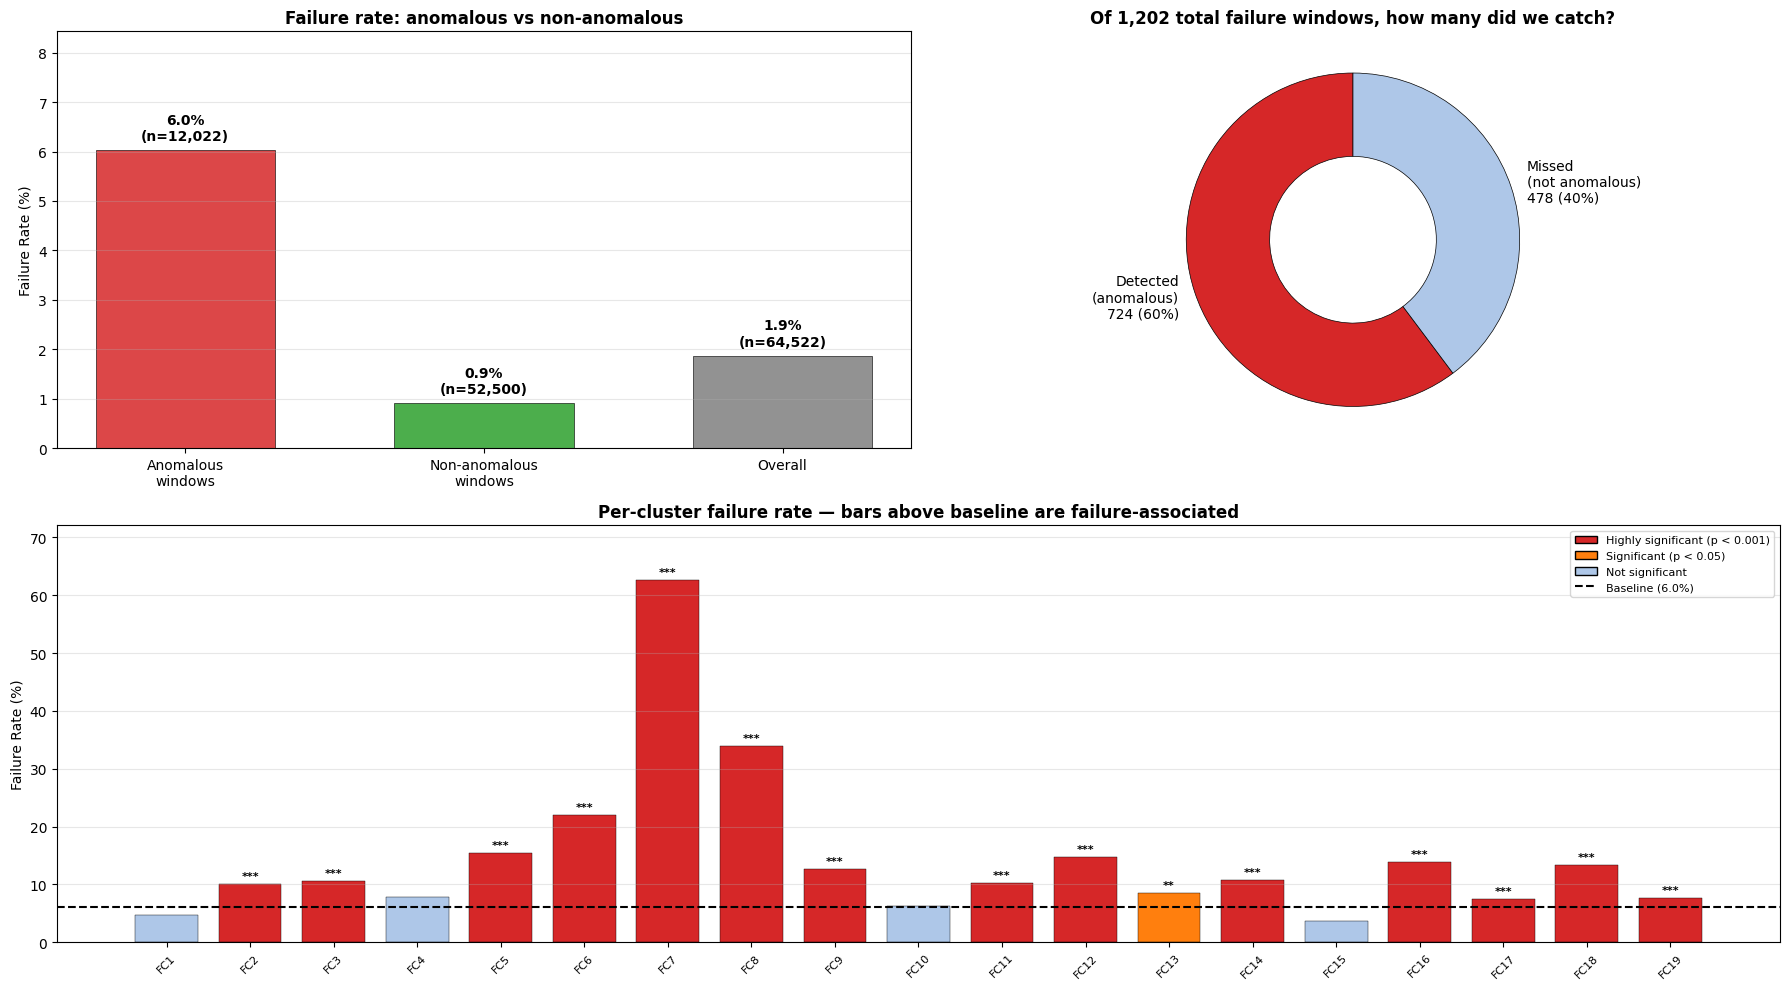

In [20]:
# ── Statistical association: anomalies vs failures ──
from scipy.stats import fisher_exact, chi2_contingency

# 1. Overall 2×2 contingency table
a = int(((all_sup['is_anomalous'] == 1) & (all_sup['label'] == 1)).sum())
b = int(((all_sup['is_anomalous'] == 1) & (all_sup['label'] == 0)).sum())
c = int(((all_sup['is_anomalous'] == 0) & (all_sup['label'] == 1)).sum())
d = int(((all_sup['is_anomalous'] == 0) & (all_sup['label'] == 0)).sum())

table = np.array([[a, b], [c, d]])
odds_ratio, p_fisher = fisher_exact(table, alternative='greater')
chi2, p_chi2, dof, expected = chi2_contingency(table)

print("="*70)
print("OVERALL: Are anomalous windows associated with failures?")
print("="*70)
print(f"\nContingency table:")
print(f"{'':>20} {'Failure':>10} {'Normal':>10} {'Total':>10}")
print(f"{'Anomalous':>20} {a:>10,} {b:>10,} {a+b:>10,}")
print(f"{'Not anomalous':>20} {c:>10,} {d:>10,} {c+d:>10,}")
print(f"{'Total':>20} {a+c:>10,} {b+d:>10,} {a+b+c+d:>10,}")
print(f"\nFailure rate in anomalous windows:     {100*a/(a+b):.1f}%")
print(f"Failure rate in non-anomalous windows:  {100*c/(c+d):.2f}%")
print(f"Overall failure rate:                   {100*(a+c)/(a+b+c+d):.2f}%")
print(f"\nFisher's exact test (one-sided): OR = {odds_ratio:.1f}, p = {p_fisher:.2e}")
print(f"Chi-squared test: χ² = {chi2:.1f}, p = {p_chi2:.2e}")
if p_fisher < 0.001:
    print("→ Highly significant: anomalous windows are strongly associated with failures.")

# 2. Per-cluster Fisher's exact test
print("\n" + "="*70)
print("PER-CLUSTER: Which FCs are significantly associated with failures?")
print("="*70)
print(f"\n{'FC':>4} {'Windows':>8} {'Fail%':>7} {'Base%':>7} {'Odds Ratio':>11} {'p-value':>12} {'Significant':>12}")
print("-"*70)

BASELINE_FAIL_PCT = 100 * all_sup.loc[anom_orig_idx, 'label'].mean()
n_total_anom = len(anom_activations)
n_total_fail = int(anom_meta['label'].sum())
n_total_norm = n_total_anom - n_total_fail

sig_clusters = []
fc_results = []  # store for plotting
for fc in sorted(heuristic_a.keys()):
    feats = heuristic_a[fc]
    fc_active = anom_activations[feats].any(axis=1)
    
    a_fc = int((fc_active & (anom_meta['label'] == 1)).sum())
    b_fc = int((fc_active & (anom_meta['label'] == 0)).sum())
    c_fc = n_total_fail - a_fc
    d_fc = n_total_norm - b_fc
    
    n_win = a_fc + b_fc
    fail_pct = 100 * a_fc / max(n_win, 1)
    
    table_fc = np.array([[a_fc, b_fc], [c_fc, d_fc]])
    or_fc, p_fc = fisher_exact(table_fc, alternative='greater')
    
    sig = '***' if p_fc < 0.001 else '**' if p_fc < 0.01 else '*' if p_fc < 0.05 else ''
    if p_fc < 0.05:
        sig_clusters.append(fc)
    
    fc_results.append({'fc': fc, 'n_win': n_win, 'fail_pct': fail_pct, 'or': or_fc, 'p': p_fc, 'sig': sig})
    print(f"FC{fc:>2} {n_win:>8} {fail_pct:>6.1f}% {BASELINE_FAIL_PCT:>6.1f}% {or_fc:>11.2f} {p_fc:>12.2e} {sig:>12}")

print(f"\nBaseline failure rate (among anomalous windows): {BASELINE_FAIL_PCT:.1f}%")
print(f"Clusters significantly enriched for failures (p<0.05): {len(sig_clusters)} / {len(heuristic_a)}")
print(f"Significant FCs: {', '.join(f'FC{fc}' for fc in sig_clusters)}")

# 3. Visualization — redesigned for clarity
fig = plt.figure(figsize=(18, 10))

# ── Top-left: Failure RATES (not raw counts) — the real comparison ──
ax1 = fig.add_subplot(2, 2, 1)
categories = ['Anomalous\nwindows', 'Non-anomalous\nwindows', 'Overall']
fail_rates_overall = [100*a/(a+b), 100*c/(c+d), 100*(a+c)/(a+b+c+d)]
bar_colors = ['#d62728', '#2ca02c', '#7f7f7f']
bars = ax1.bar(categories, fail_rates_overall, color=bar_colors, edgecolor='black',
               linewidth=0.5, width=0.6, alpha=0.85)
for bar, rate, n in zip(bars, fail_rates_overall, [a+b, c+d, a+b+c+d]):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.15,
             f'{rate:.1f}%\n(n={n:,})', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax1.set_ylabel('Failure Rate (%)')
ax1.set_title('Failure rate: anomalous vs non-anomalous', fontsize=12, fontweight='bold')
ax1.set_ylim(0, max(fail_rates_overall) * 1.4)
ax1.grid(axis='y', alpha=0.3)

# ── Top-right: What happens to failures — pie/donut ──
ax2 = fig.add_subplot(2, 2, 2)
sizes = [a, c]
labels_pie = [f'Detected\n(anomalous)\n{a} ({100*a/(a+c):.0f}%)',
              f'Missed\n(not anomalous)\n{c} ({100*c/(a+c):.0f}%)']
colors_pie = ['#d62728', '#aec7e8']
wedges, texts = ax2.pie(sizes, labels=labels_pie, colors=colors_pie,
                        startangle=90, wedgeprops=dict(width=0.5, edgecolor='black', linewidth=0.5))
for t in texts:
    t.set_fontsize(10)
ax2.set_title(f'Of {a+c:,} total failure windows, how many did we catch?',
              fontsize=12, fontweight='bold')

# ── Bottom: Per-cluster failure rates with significance markers ──
ax3 = fig.add_subplot(2, 1, 2)
fc_ids = [r['fc'] for r in fc_results]
fail_pcts = [r['fail_pct'] for r in fc_results]
p_vals = [r['p'] for r in fc_results]
bar_colors = ['#d62728' if p < 0.001 else '#ff7f0e' if p < 0.05 else '#aec7e8' for p in p_vals]

x = np.arange(len(fc_ids))
bars = ax3.bar(x, fail_pcts, color=bar_colors, edgecolor='black', linewidth=0.3, width=0.75)

# Add significance stars on top
for i, (bar, r) in enumerate(zip(bars, fc_results)):
    if r['sig']:
        ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 r['sig'], ha='center', va='bottom', fontsize=8, fontweight='bold')

ax3.axhline(BASELINE_FAIL_PCT, color='black', ls='--', linewidth=1.5,
            label=f'Baseline failure rate ({BASELINE_FAIL_PCT:.1f}%)')
ax3.set_xticks(x)
ax3.set_xticklabels([f'FC{fc}' for fc in fc_ids], rotation=45, fontsize=8)
ax3.set_ylabel('Failure Rate (%)')
ax3.set_title('Per-cluster failure rate — bars above baseline are failure-associated',
              fontsize=12, fontweight='bold')
ax3.legend(handles=[
    Patch(facecolor='#d62728', edgecolor='black', label='Highly significant (p < 0.001)'),
    Patch(facecolor='#ff7f0e', edgecolor='black', label='Significant (p < 0.05)'),
    Patch(facecolor='#aec7e8', edgecolor='black', label='Not significant'),
    plt.Line2D([0],[0], color='black', ls='--', linewidth=1.5, label=f'Baseline ({BASELINE_FAIL_PCT:.1f}%)')
], fontsize=8, loc='upper right')
ax3.grid(axis='y', alpha=0.3)
ax3.set_ylim(0, max(fail_pcts) * 1.15)

plt.tight_layout()
plt.show()

### 4.2 Operational State Context: Are Some Clusters Just Normal Operations?

Scheiblauer (2026) showed that this train has 4 operational states: standing (48%), deceleration (20%), cruising (17%), accelerating (14%). Some of our non-significant clusters might simply fire during specific operational states (e.g., deceleration) rather than indicating degradation.

We classify each window by mean speed and check whether non-significant clusters are explained by operational state rather than failure.

Operational state distribution:

State            All windows    Anomalous      Failure
------------------------------------------------------------
Standing          15,090 (23.4%)    6,762 (56.2%)      736 (61.2%)
Low speed          7,097 (11.0%)      687 ( 5.7%)      103 ( 8.6%)
Moving            42,335 (65.6%)    4,573 (38.0%)      363 (30.2%)

Per-cluster operational state breakdown (% of windows where FC fires)

  FC  Fail%   Sig   Standing    Low spd     Moving Dominant state      
---------------------------------------------------------------------------
FC 1   4.8%            99.4%       0.1%       0.4% Standing            
FC 2  10.1%   ***      96.3%       0.7%       3.0% Standing            
FC 3  10.6%   ***      46.2%      32.5%      21.2% Standing            
FC 4   7.8%            23.5%      35.9%      40.6% Moving              
FC 5  15.4%   ***      33.4%      28.2%      38.4% Moving              
FC 6  22.0%   ***      95.3%       2.2%       2.5% Standing           

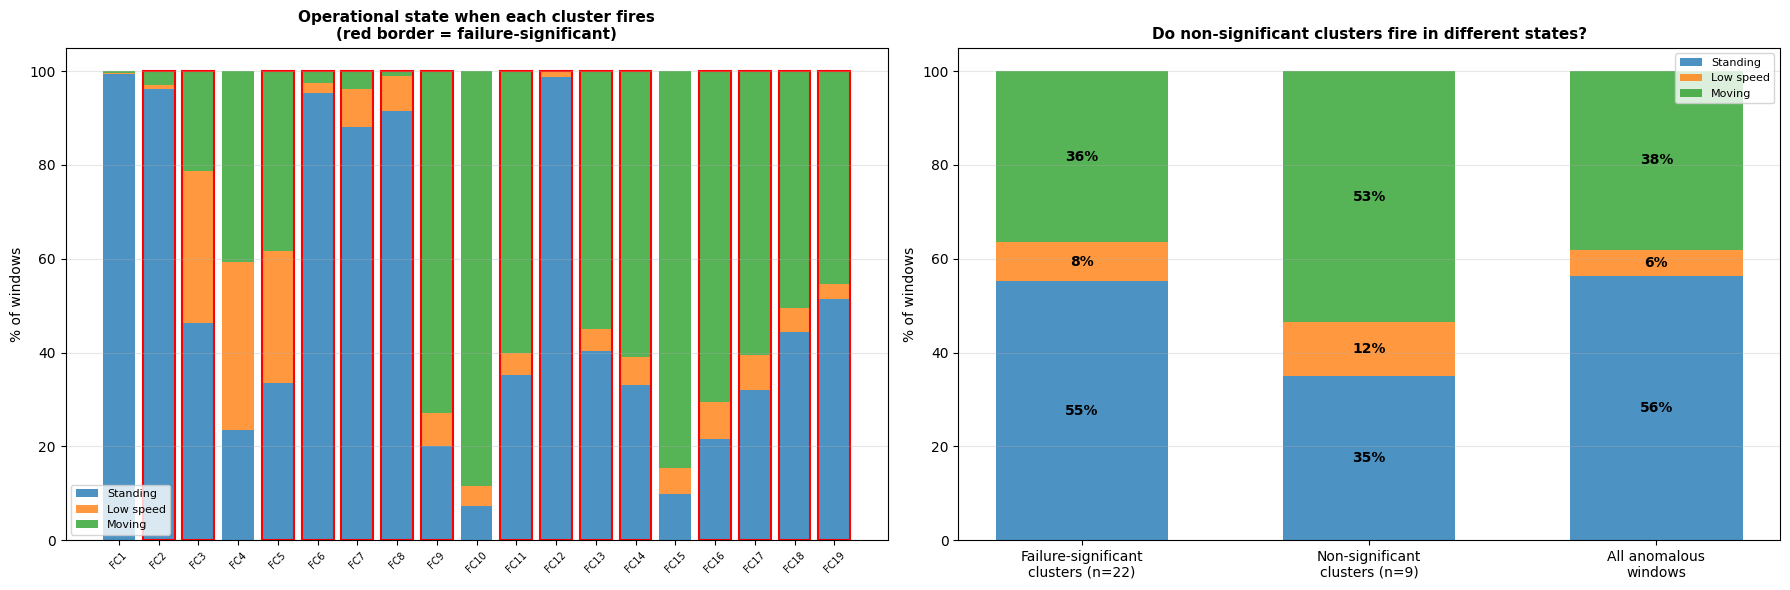


INTERPRETATION:
  Non-significant clusters (n=4):
    FC1: 4.8% failure, fires mostly during Standing (99%)
    FC4: 7.8% failure, fires mostly during Moving (41%)
    FC10: 6.3% failure, fires mostly during Moving (88%)
    FC15: 3.7% failure, fires mostly during Moving (85%)

  If non-significant clusters fire predominantly in one operational state,
  they may represent normal operational patterns, not degradation.


In [21]:
# ── Operational state analysis: are non-significant clusters just normal operations? ──
# Following Scheiblauer (2026): classify windows by speed into operational states
# Our windows are 6-min (350 s), not the short segments Scheiblauer uses, so we use mean speed as a proxy

# Define operational states based on mean speed
# Values are min-max normalized (0-1 range), thresholds based on data distribution
speed = all_sup['TRAIN_SPEED_ACTUAL_mean']
speed_max = all_sup['TRAIN_SPEED_ACTUAL_max']

# Standing: mean speed ≈ 0 (train not moving most of the window)
# Mixed/low: train moving slowly (transitioning, partial stops)
# Moving: train cruising at significant speed
all_sup['op_state'] = pd.cut(speed,
    bins=[-0.001, 0.05, 0.25, 1.1],
    labels=['Standing', 'Low speed', 'Moving'])

# Also for anomalous windows
anom_speed = all_sup.loc[anom_orig_idx, 'TRAIN_SPEED_ACTUAL_mean']
anom_state = all_sup.loc[anom_orig_idx, 'op_state']

print("Operational state distribution:")
print("="*60)
print(f"\n{'State':<15} {'All windows':>12} {'Anomalous':>12} {'Failure':>12}")
print("-"*60)
for state in ['Standing', 'Low speed', 'Moving']:
    n_all = (all_sup['op_state'] == state).sum()
    n_anom = (all_sup.loc[anom_orig_idx, 'op_state'] == state).sum()
    n_fail = all_sup.loc[(all_sup['op_state'] == state) & (all_sup['label'] == 1)].shape[0]
    pct_all = 100 * n_all / len(all_sup)
    pct_anom = 100 * n_anom / len(anom_orig_idx)
    pct_fail = 100 * n_fail / max(int(all_sup['label'].sum()), 1)
    print(f"{state:<15} {n_all:>8,} ({pct_all:>4.1f}%) {n_anom:>8,} ({pct_anom:>4.1f}%) {n_fail:>8,} ({pct_fail:>4.1f}%)")

# Per-cluster: which operational state does each cluster fire in?
print("\n" + "="*70)
print("Per-cluster operational state breakdown (% of windows where FC fires)")
print("="*70)
print(f"\n{'FC':>4} {'Fail%':>6} {'Sig':>5} {'Standing':>10} {'Low spd':>10} {'Moving':>10} {'Dominant state':<20}")
print("-"*75)

non_sig_fcs = []
sig_fcs = []

# Get significance from earlier (recalculate quickly)
n_total_anom = len(anom_activations)
n_total_fail = int(anom_meta['label'].sum())
n_total_norm = n_total_anom - n_total_fail

for fc in sorted(heuristic_a.keys()):
    feats = heuristic_a[fc]
    fc_active = anom_activations[feats].any(axis=1)
    
    # Failure rate
    n_win = int(fc_active.sum())
    if n_win == 0: continue
    n_fail = int(all_sup.loc[anom_orig_idx[fc_active.values], 'label'].sum())
    fail_pct = 100 * n_fail / max(n_win, 1)
    
    # Significance
    a_fc = int((fc_active & (anom_meta['label'] == 1)).sum())
    b_fc = int((fc_active & (anom_meta['label'] == 0)).sum())
    c_fc = n_total_fail - a_fc
    d_fc = n_total_norm - b_fc
    from scipy.stats import fisher_exact
    _, p_fc = fisher_exact(np.array([[a_fc, b_fc], [c_fc, d_fc]]), alternative='greater')
    sig = '***' if p_fc < 0.001 else '**' if p_fc < 0.01 else '*' if p_fc < 0.05 else ''
    
    # Operational state breakdown
    fc_orig_idx = anom_orig_idx[fc_active.values]
    fc_states = all_sup.loc[fc_orig_idx, 'op_state']
    state_pcts = {}
    for state in ['Standing', 'Low speed', 'Moving']:
        state_pcts[state] = 100 * (fc_states == state).sum() / len(fc_states)
    
    dominant = max(state_pcts, key=state_pcts.get)
    
    if not sig:
        non_sig_fcs.append((fc, fail_pct, state_pcts, dominant))
    else:
        sig_fcs.append((fc, fail_pct, state_pcts, dominant))
    
    print(f"FC{fc:>2} {fail_pct:>5.1f}% {sig:>5} {state_pcts['Standing']:>9.1f}% {state_pcts['Low speed']:>9.1f}% {state_pcts['Moving']:>9.1f}% {dominant:<20}")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Left: Stacked bar — all clusters colored by operational state
ax = axes[0]
fc_ids = sorted(heuristic_a.keys())
standing_pcts, low_pcts, moving_pcts = [], [], []
bar_edge_colors = []

for fc in fc_ids:
    feats = heuristic_a[fc]
    fc_active = anom_activations[feats].any(axis=1)
    fc_orig_idx_local = anom_orig_idx[fc_active.values]
    fc_states = all_sup.loc[fc_orig_idx_local, 'op_state']
    n = len(fc_states)
    standing_pcts.append(100 * (fc_states == 'Standing').sum() / max(n, 1))
    low_pcts.append(100 * (fc_states == 'Low speed').sum() / max(n, 1))
    moving_pcts.append(100 * (fc_states == 'Moving').sum() / max(n, 1))
    
    # Edge color: red for significant, grey for not
    a_fc = int((anom_activations[heuristic_a[fc]].any(axis=1) & (anom_meta['label'] == 1)).sum())
    b_fc = int((anom_activations[heuristic_a[fc]].any(axis=1) & (anom_meta['label'] == 0)).sum())
    c_fc = n_total_fail - a_fc
    d_fc = n_total_norm - b_fc
    _, p_fc = fisher_exact(np.array([[a_fc, b_fc], [c_fc, d_fc]]), alternative='greater')
    bar_edge_colors.append('red' if p_fc < 0.05 else 'grey')

x = np.arange(len(fc_ids))
ax.bar(x, standing_pcts, label='Standing', color='#1f77b4', alpha=0.8)
ax.bar(x, low_pcts, bottom=standing_pcts, label='Low speed', color='#ff7f0e', alpha=0.8)
ax.bar(x, moving_pcts, bottom=np.array(standing_pcts)+np.array(low_pcts), label='Moving', color='#2ca02c', alpha=0.8)

# Add edge highlights for significant clusters
for i, ec in enumerate(bar_edge_colors):
    if ec == 'red':
        ax.bar(x[i], 100, fill=False, edgecolor='red', linewidth=1.5, linestyle='-')

ax.set_xticks(x)
ax.set_xticklabels([f'FC{fc}' for fc in fc_ids], rotation=45, fontsize=7)
ax.set_ylabel('% of windows')
ax.set_title('Operational state when each cluster fires\n(red border = failure-significant)', fontsize=11, fontweight='bold')
ax.legend(fontsize=8)
ax.grid(axis='y', alpha=0.3)

# Right: Compare non-significant vs significant clusters
ax = axes[1]
if non_sig_fcs and sig_fcs:
    # Average state distribution for sig vs non-sig
    sig_standing = np.mean([s['Standing'] for _, _, s, _ in sig_fcs])
    sig_low = np.mean([s['Low speed'] for _, _, s, _ in sig_fcs])
    sig_moving = np.mean([s['Moving'] for _, _, s, _ in sig_fcs])
    
    nonsig_standing = np.mean([s['Standing'] for _, _, s, _ in non_sig_fcs])
    nonsig_low = np.mean([s['Low speed'] for _, _, s, _ in non_sig_fcs])
    nonsig_moving = np.mean([s['Moving'] for _, _, s, _ in non_sig_fcs])
    
    # Overall anomalous distribution for reference
    overall_standing = 100 * (all_sup.loc[anom_orig_idx, 'op_state'] == 'Standing').sum() / len(anom_orig_idx)
    overall_low = 100 * (all_sup.loc[anom_orig_idx, 'op_state'] == 'Low speed').sum() / len(anom_orig_idx)
    overall_moving = 100 * (all_sup.loc[anom_orig_idx, 'op_state'] == 'Moving').sum() / len(anom_orig_idx)
    
    categories = ['Failure-significant\nclusters (n=22)', 'Non-significant\nclusters (n=9)', 'All anomalous\nwindows']
    standing_vals = [sig_standing, nonsig_standing, overall_standing]
    low_vals = [sig_low, nonsig_low, overall_low]
    moving_vals = [sig_moving, nonsig_moving, overall_moving]
    
    x2 = np.arange(3)
    w = 0.6
    ax.bar(x2, standing_vals, w, label='Standing', color='#1f77b4', alpha=0.8)
    ax.bar(x2, low_vals, w, bottom=standing_vals, label='Low speed', color='#ff7f0e', alpha=0.8)
    ax.bar(x2, moving_vals, w, bottom=np.array(standing_vals)+np.array(low_vals), label='Moving', color='#2ca02c', alpha=0.8)
    
    # Annotate
    for i in range(3):
        ax.text(x2[i], standing_vals[i]/2, f'{standing_vals[i]:.0f}%', ha='center', va='center', fontsize=10, fontweight='bold')
        ax.text(x2[i], standing_vals[i] + low_vals[i]/2, f'{low_vals[i]:.0f}%', ha='center', va='center', fontsize=10, fontweight='bold')
        ax.text(x2[i], standing_vals[i] + low_vals[i] + moving_vals[i]/2, f'{moving_vals[i]:.0f}%', ha='center', va='center', fontsize=10, fontweight='bold')
    
    ax.set_xticks(x2)
    ax.set_xticklabels(categories)
    ax.set_ylabel('% of windows')
    ax.set_title('Do non-significant clusters fire in different states?', fontsize=11, fontweight='bold')
    ax.legend(fontsize=8)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Interpretation
print("\nINTERPRETATION:")
print(f"  Non-significant clusters (n={len(non_sig_fcs)}):")
for fc, fp, sp, dom in non_sig_fcs:
    print(f"    FC{fc}: {fp:.1f}% failure, fires mostly during {dom} ({sp[dom]:.0f}%)")
print()
print("  If non-significant clusters fire predominantly in one operational state,")
print("  they may represent normal operational patterns, not degradation.")

### 4.3 Temporal Pattern Analysis: When Does Each FC Fire Relative to Failure Onset?

Every window is assigned a **phase** relative to the canonical failure events (raw failure flag):

| Phase | Time relative to onset | Source |
|---|---|---|
| early | 6 days to 1 day before | early-hit window of Steiner et al. (RAMS 2026) and Helm (2025, p96) |
| imminent | last 24 h before | Helm's 24 h precursor look-back (2025, p83–84) |
| during | inside the recorded failure | |
| normal | more than 7 days before any failure and more than 24 h after the previous one | baseline |

**Drift control.** 11 of the 21 failures fall in the test period, where all FCs fire more often (see §1 and §4.6). Every comparison therefore uses the normal-phase rate of the *same period* (train or test) as its baseline:
- **Enrichment:** observed activations divided by the activations expected at the same-period normal rate.
- **Event-level test:** the number of events in which the FC fires in a phase, compared with the number expected by chance at the same-period normal rate (Poisson-binomial tail). Counting events instead of windows is robust to autocorrelation within an event. It also does not require an FC to fire in most events, since a pattern may be specific to one failure type.
- **Lead time:** median hours between the first activation in the last 24 h and onset.

Classification (descriptive, for expert review):
- **early-warning**: early enrichment ≥ 1.5 and event test p < 0.05 (6 days to 1 day before onset)
- **short-term precursor**: imminent enrichment ≥ 1.5 and event test p < 0.05 (last 24 h)
- **detection-only**: during enrichment ≥ 1.5 and event test p < 0.05
- **weak / mixed**: any enrichment ≥ 1.2
- **background**: none of the above

Observable failure events: 21/21

  FC  normal_rate_train_%  normal_rate_test_%  early_rate_%  imminent_rate_%  during_rate_%  enrich_early  enrich_imminent  enrich_during  events_early  expected_early  p_early  events_24h  expected_24h  p_24h  events_during  expected_during  p_during  median_lead_24h_h              pattern
 FC1                 4.12                3.06          4.85             4.36          15.65          1.37             1.23           4.28            20           20.08     0.91          14         17.78   1.00             14             9.83      0.02              13.85       detection-only
 FC2                 3.70                6.26          7.26             8.66          58.75          1.42             1.71          12.22            20           20.16     0.99          14         17.91   1.00             14            11.56      0.13              13.96         weak / mixed
 FC3                 0.27                2.36          1.32             2.30           5.7

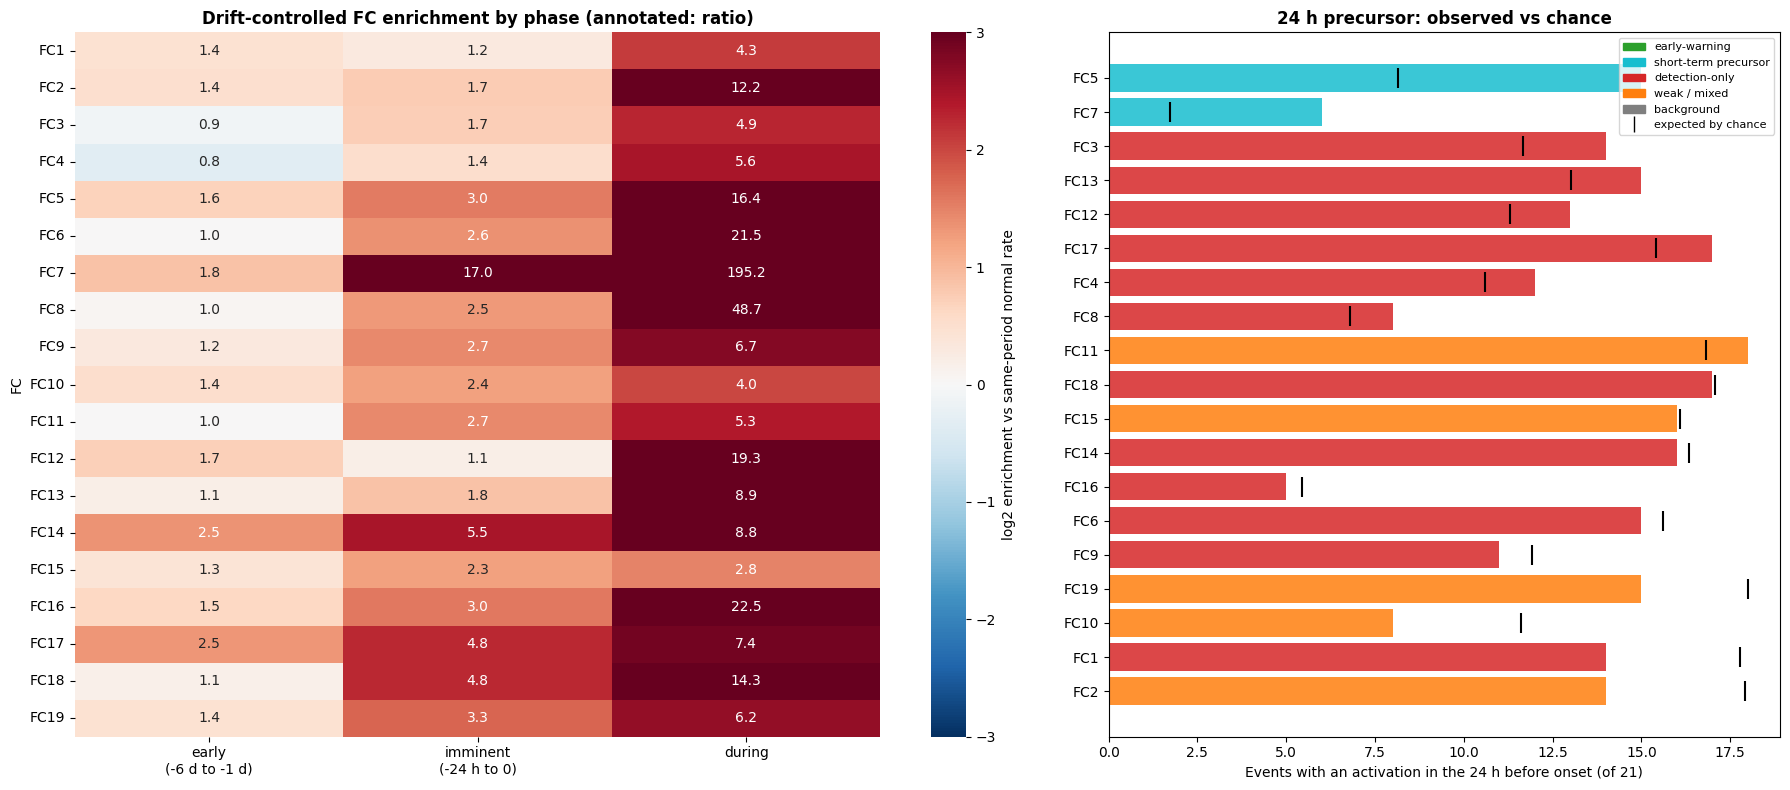

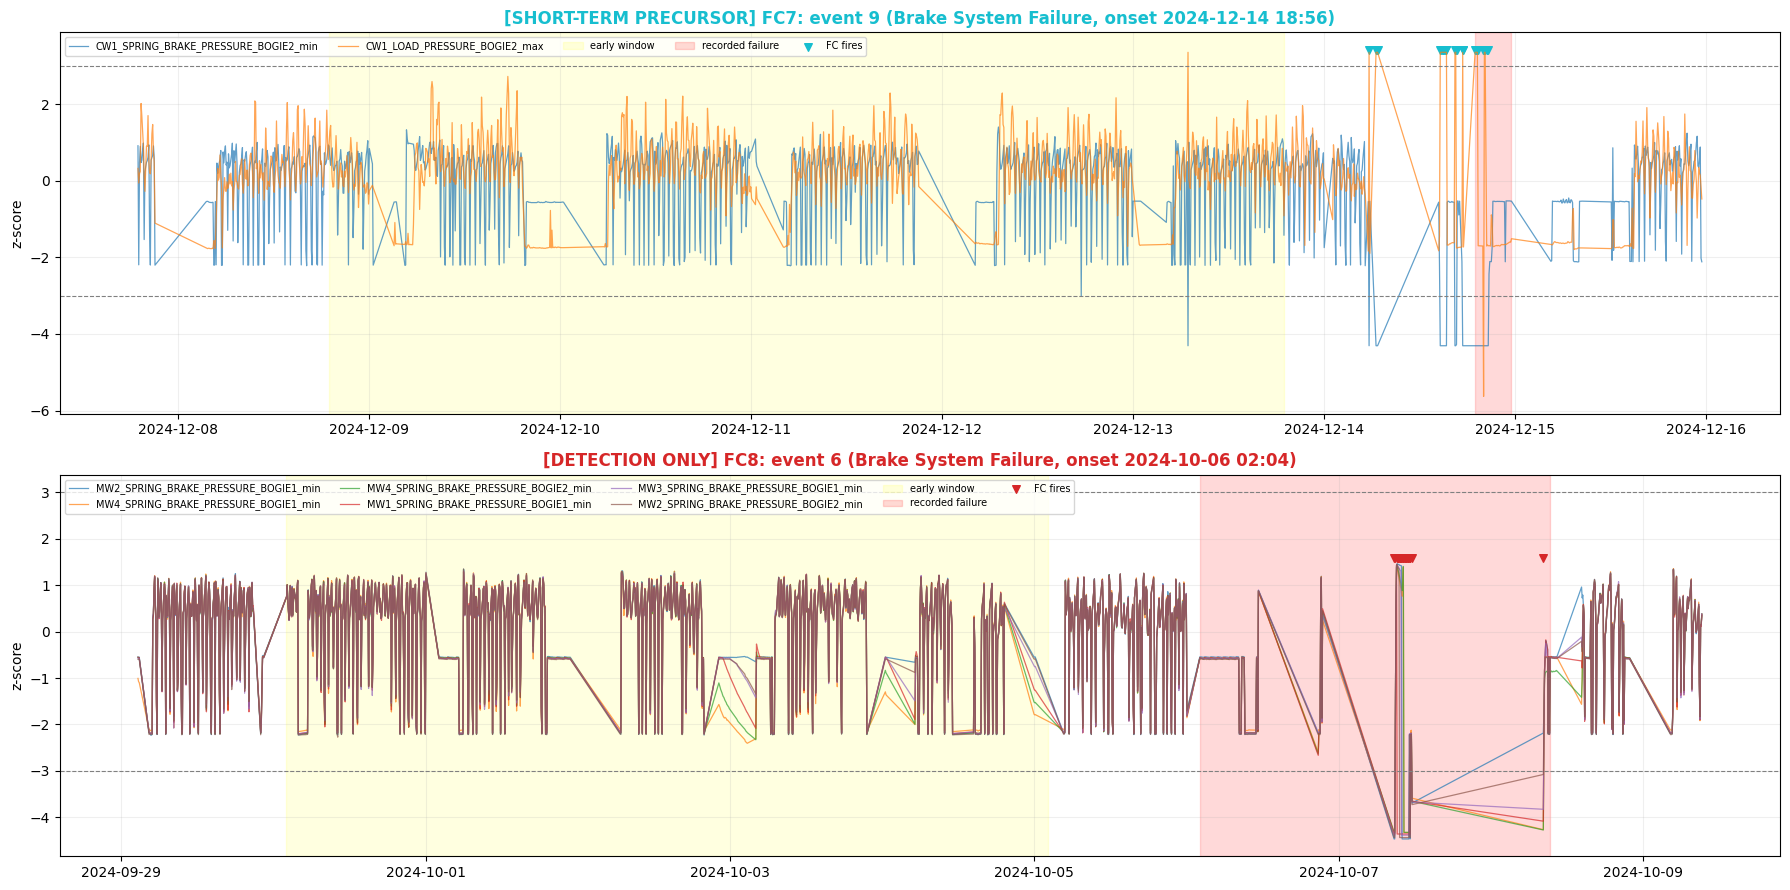

In [22]:
# ── Temporal pattern analysis: drift-controlled FC activation by phase relative to failure onset ──
from scipy.stats import binom

fc_ids = sorted(heuristic_a.keys())
fc_act_all = pd.DataFrame(False, index=all_sup.index, columns=fc_ids)
for fc in fc_ids:
    fc_act_all.loc[anom_orig_idx, fc] = anom_activations[heuristic_a[fc]].any(axis=1).values

phase = all_sup['phase'].values
ev_id = all_sup['ev_id'].values
offset = all_sup['ev_offset_h'].values
split_arr = all_sup['split'].values
observable = [e for e in fail_events.index
              if ((ev_id == e) & np.isin(phase, ['early', 'imminent', 'during'])).any()]
ev_split = fail_events['split'].to_dict()


def poisson_binomial_sf(k, probs):
    """P(X >= k) for a sum of independent Bernoulli(p_i)."""
    dist = np.zeros(len(probs) + 1)
    dist[0] = 1.0
    for q in probs:
        nxt = dist * (1 - q)
        nxt[1:] += dist[:-1] * q
        dist = nxt
    return float(dist[k:].sum())


rows = []
for fc in fc_ids:
    act = fc_act_all[fc].values
    base = {s: act[(phase == 'normal') & (split_arr == s)].mean() for s in ('train', 'test')}
    enr, rate = {}, {}
    for ph in ('early', 'imminent', 'during'):
        m = phase == ph
        expected = sum((m & (split_arr == s)).sum() * base[s] for s in base)
        enr[ph] = act[m].sum() / expected if expected > 0 else np.nan
        rate[ph] = act[m].mean()
    # Event-level test: number of events in which the FC fires in a phase, vs the number expected
    # by chance at the same-period normal rate (Poisson-binomial tail). Counting events instead of
    # windows makes the test robust to autocorrelation within an event, and it does not require an FC
    # to fire in most events (an FC may be specific to one failure type).
    obs = {ph: 0 for ph in ('early', 'imminent', 'during')}
    probs = {ph: [] for ph in obs}
    leads24 = []
    for e in observable:
        b = base[ev_split[e]]
        for ph in obs:
            m = (ev_id == e) & (phase == ph)
            if m.any():
                probs[ph].append(1 - (1 - b) ** m.sum())
                if (act & m).any():
                    obs[ph] += 1
                    if ph == 'imminent':
                        leads24.append(-np.nanmin(offset[act & m]))
    p = {ph: poisson_binomial_sf(obs[ph], probs[ph]) for ph in obs}
    exp_ev = {ph: float(np.sum(probs[ph])) for ph in obs}
    if enr['early'] >= 1.5 and p['early'] < 0.05:
        pattern = 'early-warning'
    elif enr['imminent'] >= 1.5 and p['imminent'] < 0.05:
        pattern = 'short-term precursor'
    elif enr['during'] >= 1.5 and p['during'] < 0.05:
        pattern = 'detection-only'
    elif np.nanmax(list(enr.values())) >= 1.2:
        pattern = 'weak / mixed'
    else:
        pattern = 'background'
    rows.append({'FC': f'FC{fc}', 'fc_id': fc,
                 'normal_rate_train_%': 100 * base['train'], 'normal_rate_test_%': 100 * base['test'],
                 'early_rate_%': 100 * rate['early'], 'imminent_rate_%': 100 * rate['imminent'], 'during_rate_%': 100 * rate['during'],
                 'enrich_early': enr['early'], 'enrich_imminent': enr['imminent'], 'enrich_during': enr['during'],
                 'events_early': obs['early'], 'expected_early': exp_ev['early'], 'p_early': p['early'],
                 'events_24h': obs['imminent'], 'expected_24h': exp_ev['imminent'], 'p_24h': p['imminent'],
                 'events_during': obs['during'], 'expected_during': exp_ev['during'], 'p_during': p['during'],
                 'median_lead_24h_h': np.median(leads24) if leads24 else np.nan, 'pattern': pattern})
fc_temporal = pd.DataFrame(rows)

print(f'Observable failure events: {len(observable)}/{len(fail_events)}\n')
print(fc_temporal.drop(columns='fc_id').round(2).to_string(index=False))
print('\nPattern counts:', fc_temporal['pattern'].value_counts().to_dict())
print('Enrichment uses the same-period (train/test) normal rate as baseline; event counts are compared '
      'with the number expected by chance at that rate (Poisson-binomial p-values).')

fig, axes = plt.subplots(1, 2, figsize=(18, 8), gridspec_kw={'width_ratios': [3, 2]})
enr_tab = fc_temporal.set_index('FC')[['enrich_early', 'enrich_imminent', 'enrich_during']]
sns.heatmap(np.log2(enr_tab.clip(lower=1/16, upper=16)), ax=axes[0], cmap='RdBu_r', center=0, vmin=-3, vmax=3,
            annot=enr_tab.round(1), fmt='', cbar_kws={'label': 'log2 enrichment vs same-period normal rate'})
axes[0].set_xticklabels(['early\n(-6 d to -1 d)', 'imminent\n(-24 h to 0)', 'during'])
axes[0].set_title('Drift-controlled FC enrichment by phase (annotated: ratio)', fontweight='bold')

colors = {'early-warning': '#2ca02c', 'short-term precursor': '#17becf', 'detection-only': '#d62728',
          'weak / mixed': '#ff7f0e', 'background': '#7f7f7f'}
d = fc_temporal.copy()
d['excess'] = d['events_24h'] - d['expected_24h']
d = d.sort_values('excess', ascending=False)
axes[1].barh(d['FC'], d['events_24h'], color=[colors[p] for p in d['pattern']], alpha=0.85, label='observed')
axes[1].scatter(d['expected_24h'], d['FC'], color='black', marker='|', s=200, label='expected by chance')
axes[1].invert_yaxis()
axes[1].set_xlabel(f'Events with an activation in the 24 h before onset (of {len(observable)})')
axes[1].set_title('24 h precursor: observed vs chance', fontweight='bold')
axes[1].legend(handles=[Patch(color=c, label=p) for p, c in colors.items()] +
               [plt.Line2D([], [], color='black', marker='|', ls='', markersize=12, label='expected by chance')], fontsize=8)
plt.tight_layout()
plt.show()

examples = []
ew = fc_temporal[fc_temporal.pattern == 'early-warning'].sort_values('enrich_early', ascending=False)
sp_ = fc_temporal[fc_temporal.pattern == 'short-term precursor'].sort_values('enrich_imminent', ascending=False)
do = fc_temporal[fc_temporal.pattern == 'detection-only'].sort_values('enrich_during', ascending=False)
if len(ew): examples.append((int(ew.iloc[0].fc_id), 'EARLY WARNING', '#2ca02c'))
if len(sp_): examples.append((int(sp_.iloc[0].fc_id), 'SHORT-TERM PRECURSOR', '#17becf'))
if len(do): examples.append((int(do.iloc[0].fc_id), 'DETECTION ONLY', '#d62728'))
if examples:
    fig, axes = plt.subplots(len(examples), 1, figsize=(18, 4.5 * len(examples)))
    axes = np.atleast_1d(axes)
    for ax, (fc, title, col) in zip(axes, examples):
        act = fc_act_all[fc].values
        counts = {e: int((act & (ev_id == e) & np.isin(phase, ['early', 'imminent', 'during'])).sum()) for e in observable}
        e = max(counts, key=counts.get)
        ev = fail_events.loc[e]
        view = (all_sup['window_end'] >= ev.start - pd.Timedelta(days=7)) & (all_sup['window_end'] <= ev.end + pd.Timedelta(days=1))
        for f in heuristic_a[fc][:6]:
            ax.plot(all_sup.loc[view, 'window_end'], (all_sup.loc[view, f] - feat_means[f]) / feat_stds[f], lw=0.9, alpha=0.7, label=f)
        ax.axvspan(ev.start - pd.Timedelta(days=6), ev.start - pd.Timedelta(days=1), color='yellow', alpha=0.12, label='early window')
        ax.axvspan(ev.start, ev.end, color='red', alpha=0.15, label='recorded failure')
        fires = all_sup.loc[view & fc_act_all[fc], 'window_end']
        ax.scatter(fires, np.full(len(fires), ax.get_ylim()[1] * 0.9), marker='v', color=col, s=30, label='FC fires')
        ax.axhline(Z_THRESH, color='grey', ls='--', lw=0.8); ax.axhline(-Z_THRESH, color='grey', ls='--', lw=0.8)
        ax.set_title(f'[{title}] FC{fc}: event {e} ({ev.event_type}, onset {ev.start:%Y-%m-%d %H:%M})', color=col, fontweight='bold')
        ax.set_ylabel('z-score'); ax.legend(fontsize=7, ncol=5, loc='upper left'); ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

### 4.4 Failure-Related Days vs Normal Days: Cluster Activation Contrast

A **failure-related day** is any calendar day that overlaps a recorded failure or the 6.2 h before its onset (the label horizon), taken from the canonical event table. All other days are normal days. We compare FC activation rates across all failure-related days and all normal days (aggregate, not cherry-picked).

Failure days: 26 days, 1490 anomalous windows
Normal days:  333 days, 10532 anomalous windows



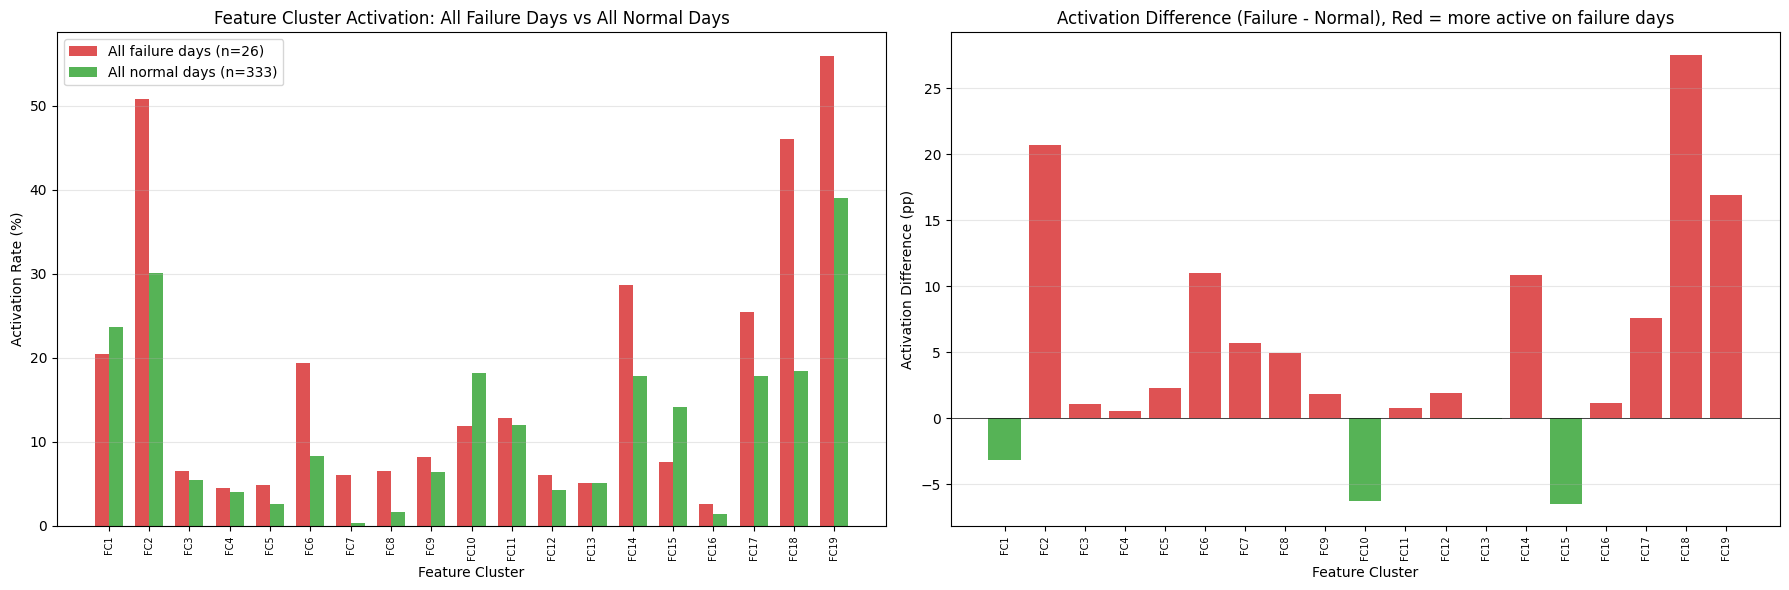


  FC  Fail Days  Normal Days  Diff (pp)  Interpretation
FC 1      20.5%        23.6%      -3.2  similar
FC 2      50.8%        30.1%     +20.7  FAILURE-SPECIFIC
FC 3       6.6%         5.5%      +1.1  similar
FC 4       4.6%         4.0%      +0.6  similar
FC 5       4.9%         2.6%      +2.3  similar
FC 6      19.3%         8.3%     +11.0  failure-leaning
FC 7       6.1%         0.4%      +5.7  failure-leaning
FC 8       6.6%         1.6%      +4.9  similar
FC 9       8.3%         6.4%      +1.8  similar
FC10      11.9%        18.2%      -6.3  normal-leaning
FC11      12.8%        12.1%      +0.8  similar
FC12       6.1%         4.2%      +1.9  similar
FC13       5.1%         5.2%      -0.1  similar
FC14      28.7%        17.8%     +10.9  failure-leaning
FC15       7.7%        14.1%      -6.5  normal-leaning
FC16       2.6%         1.5%      +1.1  similar
FC17      25.4%        17.9%      +7.6  failure-leaning
FC18      46.0%        18.4%     +27.5  FAILURE-SPECIFIC
FC19      55.9%

In [23]:
# ── Failure Day vs Normal Day comparison ──
# Compare cluster activation across ALL failure days vs ALL normal days (aggregate)

# Compute daily statistics
anom_meta["date"] = anom_meta["window_end"].dt.date
daily = anom_meta.groupby("date").agg(
    n_windows=("label", "size"),
    n_failures=("label", "sum")
).reset_index()
daily["fail_pct"] = 100 * daily["n_failures"] / daily["n_windows"]

# Failure-related days: calendar days overlapping [onset - 6.2 h, end] of a canonical failure event
failure_days = set()
for ev in fail_events.itertuples():
    for d in pd.date_range((ev.start - pd.Timedelta(seconds=HORIZON_S)).normalize(), ev.end.normalize(), freq='D'):
        failure_days.add(d.date())
failure_days &= set(daily["date"].values)
normal_days = set(daily["date"].values) - failure_days

fail_mask = anom_meta["date"].isin(failure_days)
norm_mask = anom_meta["date"].isin(normal_days)

print(f"Failure days: {len(failure_days)} days, {fail_mask.sum()} anomalous windows")
print(f"Normal days:  {len(normal_days)} days, {norm_mask.sum()} anomalous windows")
print()

# Compute activation rate per feature cluster for failure vs normal days
fc_ids = sorted(heuristic_a.keys())

fail_rates = []
norm_rates = []
for fc in fc_ids:
    feats = heuristic_a[fc]
    fc_act = anom_activations[feats].any(axis=1)
    fail_rates.append(100 * fc_act[fail_mask].mean() if fail_mask.sum() > 0 else 0)
    norm_rates.append(100 * fc_act[norm_mask].mean() if norm_mask.sum() > 0 else 0)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Bar chart comparison
ax = axes[0]
x = np.arange(len(fc_ids))
w = 0.35
ax.bar(x - w/2, fail_rates, w, label=f"All failure days (n={len(failure_days)})", color="#d62728", alpha=0.8)
ax.bar(x + w/2, norm_rates, w, label=f"All normal days (n={len(normal_days)})", color="#2ca02c", alpha=0.8)
ax.set_xlabel("Feature Cluster")
ax.set_ylabel("Activation Rate (%)")
ax.set_title("Feature Cluster Activation: All Failure Days vs All Normal Days")
ax.set_xticks(x)
ax.set_xticklabels([f"FC{fc}" for fc in fc_ids], rotation=90, fontsize=7)
ax.legend()
ax.grid(axis="y", alpha=0.3)

# Difference plot
ax = axes[1]
diff = np.array(fail_rates) - np.array(norm_rates)
colors = ["#d62728" if d > 0 else "#2ca02c" for d in diff]
ax.bar(x, diff, color=colors, alpha=0.8)
ax.set_xlabel("Feature Cluster")
ax.set_ylabel("Activation Difference (pp)")
ax.set_title("Activation Difference (Failure - Normal), Red = more active on failure days")
ax.set_xticks(x)
ax.set_xticklabels([f"FC{fc}" for fc in fc_ids], rotation=90, fontsize=7)
ax.axhline(0, color="black", linewidth=0.5)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Print summary table and identify failure-specific clusters dynamically
print()
header = f'{"FC":>4} {"Fail Days":>10} {"Normal Days":>12} {"Diff (pp)":>10}  Interpretation'
print(header)
print("=" * 78)
failure_specific_fcs = []
for i, fc in enumerate(fc_ids):
    d = fail_rates[i] - norm_rates[i]
    if d > 20:
        tag = "FAILURE-SPECIFIC"
        failure_specific_fcs.append(fc)
    elif d > 5:
        tag = "failure-leaning"
    elif abs(d) <= 5:
        tag = "similar"
    else:
        tag = "normal-leaning"
    print(f"FC{fc:>2} {fail_rates[i]:>9.1f}% {norm_rates[i]:>11.1f}% {d:>+9.1f}  {tag}")

n_similar = sum(1 for i in range(len(fc_ids)) if abs(fail_rates[i] - norm_rates[i]) <= 5)
n_mixed = len(fc_ids) - len(failure_specific_fcs) - n_similar
print()
print(f"Summary: {len(failure_specific_fcs)} failure-specific clusters ({', '.join(f'FC{fc}' for fc in failure_specific_fcs)}), "
      f"{n_similar} similar, {n_mixed} mixed")

# Stratified by period: failure-related days are concentrated in the drifting test period
print('\nStratified by period (controls for the test-period drift):')
print(f'{"FC":>4} {"Diff train (pp)":>16} {"Diff test (pp)":>15}  Consistent?')
print('=' * 52)
day_contrast_strat = []
for fc in fc_ids:
    act = anom_activations[heuristic_a[fc]].any(axis=1)
    diffs = {}
    for sp in ('train', 'test'):
        fm, nm = fail_mask & (anom_meta['split'] == sp), norm_mask & (anom_meta['split'] == sp)
        diffs[sp] = 100 * (act[fm].mean() - act[nm].mean()) if fm.any() and nm.any() else np.nan
    consistent = 'yes' if diffs['train'] > 5 and diffs['test'] > 5 else ''
    day_contrast_strat.append({'FC': f'FC{fc}', 'diff_train_pp': diffs['train'], 'diff_test_pp': diffs['test'], 'consistent': consistent})
    print(f'FC{fc:>2} {diffs["train"]:>+15.1f} {diffs["test"]:>+15.1f}  {consistent}')
day_contrast_strat = pd.DataFrame(day_contrast_strat)
print(f'\nFCs more active on failure-related days in BOTH periods (> 5 pp): '
      f'{", ".join(day_contrast_strat.loc[day_contrast_strat.consistent == "yes", "FC"]) or "none"}')

### 4.5 Volatility Lead-Up: Does Sensor Variance Increase Before Failure Onset?

For each FC we z-score its features against the train-normal distribution and compute, per calendar day, the **within-day standard deviation** (volatility) and the **mean |z|** (level shift), averaged over the FC's features. Profiles are aligned to the onset date of each canonical event where the FC fires, and expressed relative to the normal days of the same period (train or test), which controls for the test-period drift.

- **pre-onset volatility ratio**: mean volatility on days −3 to −1 divided by the normal-day baseline. Only days *strictly before* the onset date count as warning.
- **monotonicity**: Kendall's τ of the average volatility profile over days −7 to −1 (a degradation-trend metric; Coble & Hines; see also Yin Shen collection, RESS 2024).
- The day-0 ratio is reported separately. A jump that appears only at day 0 is a sudden change, not an early warning.

Analyzing 6 clusters: FC2, FC5, FC6, FC7, FC8, FC18


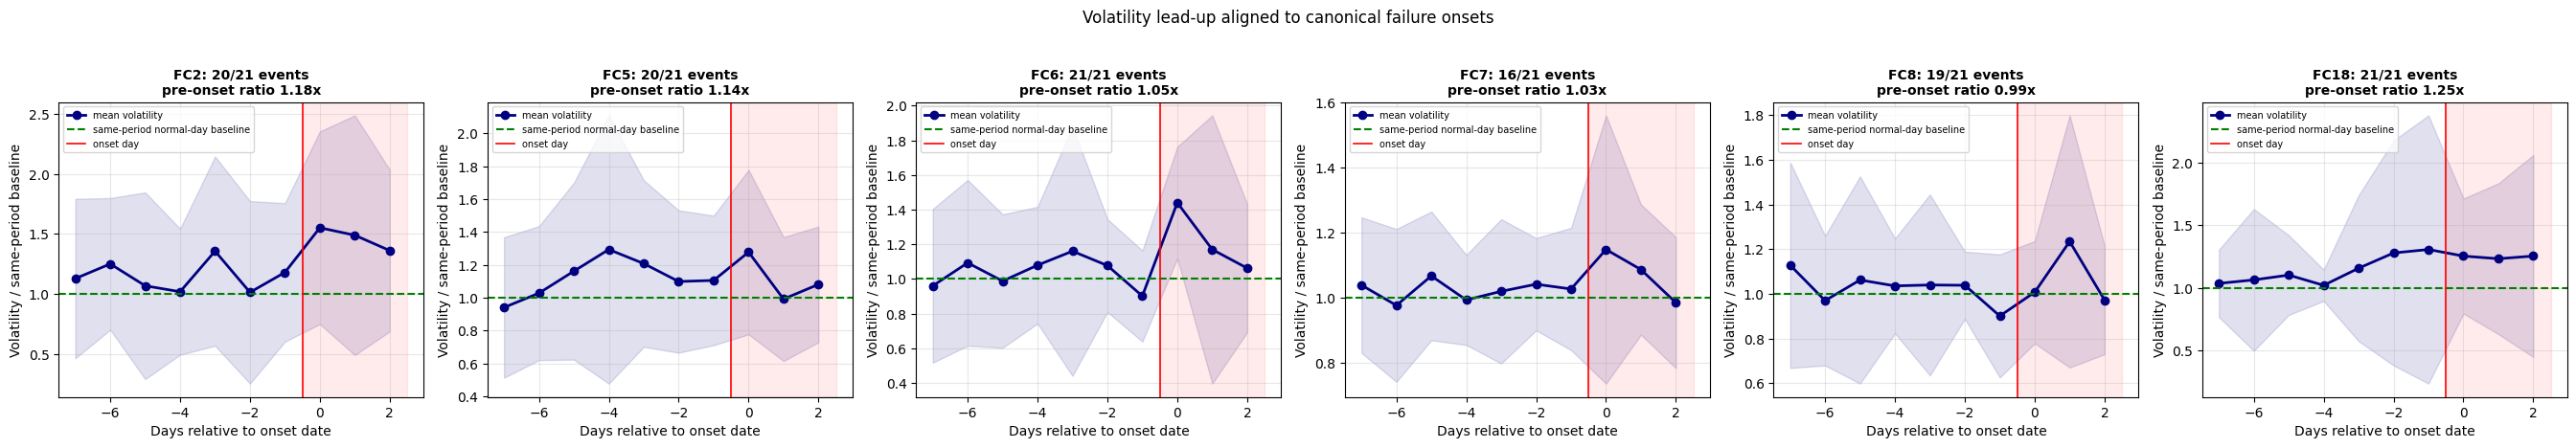

  FC events  pre_vol_ratio  day0_vol_ratio  pre_level_ratio  kendall_tau_pre  p_tau  median_event_tau                         interpretation
 FC2  20/21          1.184           1.552            1.037           -0.143  0.773             0.048    increase only at onset day (sudden)
 FC5  20/21          1.137           1.278            1.105            0.333  0.381             0.143                   no volatility change
 FC6  21/21          1.046           1.441            1.229           -0.048  1.000             0.048                   no volatility change
 FC7  16/21          1.030           1.149            1.124            0.143  0.773             0.048                   no volatility change
 FC8  19/21          0.993           1.008            1.121           -0.429  0.239             0.000                   no volatility change
FC18  21/21          1.247           1.253            1.368            0.714  0.030             0.048 moderate pre-onset volatility increase

Note: an ear

In [24]:
# ── Volatility lead-up analysis (real within-day variance, aligned to canonical onsets) ──
from scipy.stats import kendalltau

high_fail = []
for fc in fc_ids:
    act = anom_activations[heuristic_a[fc]].any(axis=1)
    if 100 * anom_meta.loc[act, 'label'].mean() > 20:
        high_fail.append(fc)
analysis_fcs = sorted(set(failure_specific_fcs) | set(high_fail) |
                      set(fc_temporal.loc[fc_temporal.pattern.isin(['early-warning', 'short-term precursor']), 'fc_id']))
print(f'Analyzing {len(analysis_fcs)} clusters: {", ".join(f"FC{fc}" for fc in analysis_fcs)}\n')

all_sup['date'] = all_sup['window_end'].dt.date
onset_dates = {e: fail_events.loc[e, 'start'].normalize() for e in fail_events.index}
non_normal_dates = set(all_sup.loc[all_sup['phase'] != 'normal', 'date'])
normal_dates = sorted(set(all_sup['date']) - non_normal_dates)
normal_dates_split = {'train': [d for d in normal_dates if pd.Timestamp(d) < SPLIT_DATE],
                      'test': [d for d in normal_dates if pd.Timestamp(d) >= SPLIT_DATE]}
OFFSETS = list(range(-7, 3))

fig, axes = plt.subplots(1, len(analysis_fcs), figsize=(4.5 * len(analysis_fcs), 4.5), squeeze=False)
var_rows = []
for ax, fc in zip(axes[0], analysis_fcs):
    feats = heuristic_a[fc]
    zf = (all_sup[feats] - feat_means[feats]) / feat_stds[feats]
    g = zf.groupby(all_sup['date'])
    daily_vol = g.std().mean(axis=1)
    daily_lvl = zf.abs().groupby(all_sup['date']).mean().mean(axis=1)
    base_vol = {sp: daily_vol.reindex(normal_dates_split[sp]).mean() for sp in ('train', 'test')}
    base_lvl = {sp: daily_lvl.reindex(normal_dates_split[sp]).mean() for sp in ('train', 'test')}

    act = fc_act_all[fc].values
    rel_events = [e for e in observable if (act & (ev_id == e) & np.isin(phase, ['early', 'imminent', 'during'])).any()]
    prof_v, prof_l, taus = [], [], []
    for e in rel_events:
        dates = [(onset_dates[e] + pd.Timedelta(days=d)).date() for d in OFFSETS]
        sp = fail_events.loc[e, 'split']
        v = daily_vol.reindex(dates).values / base_vol[sp]
        l = daily_lvl.reindex(dates).values / base_lvl[sp]
        prof_v.append(v); prof_l.append(l)
        pre = v[:7]
        if np.isfinite(pre).sum() >= 4:
            ok = np.isfinite(pre)
            taus.append(kendalltau(np.array(OFFSETS[:7])[ok], pre[ok])[0])
    prof_v, prof_l = np.array(prof_v, dtype=float), np.array(prof_l, dtype=float)
    mean_v, mean_l = np.nanmean(prof_v, axis=0), np.nanmean(prof_l, axis=0)
    pre_idx = [OFFSETS.index(d) for d in (-3, -2, -1)]
    pre_vol = np.nanmean(mean_v[pre_idx])
    pre_lvl = np.nanmean(mean_l[pre_idx])
    day0_vol = mean_v[OFFSETS.index(0)]
    tau_avg, p_tau = kendalltau(OFFSETS[:7], mean_v[:7])
    if pre_vol >= 1.5:
        tag = 'strong pre-onset volatility increase'
    elif pre_vol >= 1.2:
        tag = 'moderate pre-onset volatility increase'
    elif day0_vol >= 1.5:
        tag = 'increase only at onset day (sudden)'
    else:
        tag = 'no volatility change'
    var_rows.append({'FC': f'FC{fc}', 'events': f'{len(rel_events)}/{len(observable)}',
                     'pre_vol_ratio': pre_vol, 'day0_vol_ratio': day0_vol, 'pre_level_ratio': pre_lvl,
                     'kendall_tau_pre': tau_avg, 'p_tau': p_tau,
                     'median_event_tau': np.nanmedian(taus) if taus else np.nan, 'interpretation': tag})

    sd = np.nanstd(prof_v, axis=0)
    ax.plot(OFFSETS, mean_v, 'o-', color='navy', lw=2, label='mean volatility')
    ax.fill_between(OFFSETS, mean_v - sd, mean_v + sd, color='navy', alpha=0.12)
    ax.axhline(1.0, color='green', ls='--', label='same-period normal-day baseline')
    ax.axvspan(-0.5, max(OFFSETS) + 0.5, color='red', alpha=0.08)
    ax.axvline(-0.5, color='red', lw=1.2, label='onset day')
    ax.set_xlabel('Days relative to onset date'); ax.set_ylabel('Volatility / same-period baseline')
    ax.set_title(f'FC{fc}: {len(rel_events)}/{len(observable)} events\npre-onset ratio {pre_vol:.2f}x', fontsize=10, fontweight='bold')
    ax.legend(fontsize=7, loc='upper left'); ax.grid(alpha=0.3)
plt.suptitle('Volatility lead-up aligned to canonical failure onsets', y=1.03, fontsize=12)
plt.tight_layout()
plt.show()

fc_variance = pd.DataFrame(var_rows)
print(fc_variance.round(3).to_string(index=False))
print('\nNote: an earlier version of this cell plotted the daily mean feature level (no _std features exist)')
print('and measured the ratio on the failure day itself. The table above uses real within-day variance')
print('and judges early warning only on days strictly before the onset date.')

### 4.6 Distribution Shift per FC

Each FC's activation rate on windows far from any failure (normal phase), compared between the train and the test period. An FC that becomes much more active in the test period without failures nearby is flagged as **possibly drift-driven**, and its test-period activations should be read with care.

  FC  train_normal_rate_%  test_normal_rate_%  test_train_ratio  drift_flag
 FC1                 4.12                3.06              0.74       False
 FC2                 3.70                6.26              1.69       False
 FC3                 0.27                2.36              8.64        True
 FC4                 0.19                1.82              9.78        True
 FC5                 0.12                0.80              6.77       False
 FC6                 1.27                1.56              1.23       False
 FC7                 0.04                0.08              2.09       False
 FC8                 0.23                0.36              1.57       False
 FC9                 0.30                2.27              7.44        True
FC10                 0.23                6.59             28.92        True
FC11                 1.74                2.57              1.48       False
FC12                 0.53                0.74              1.41       False
FC13        

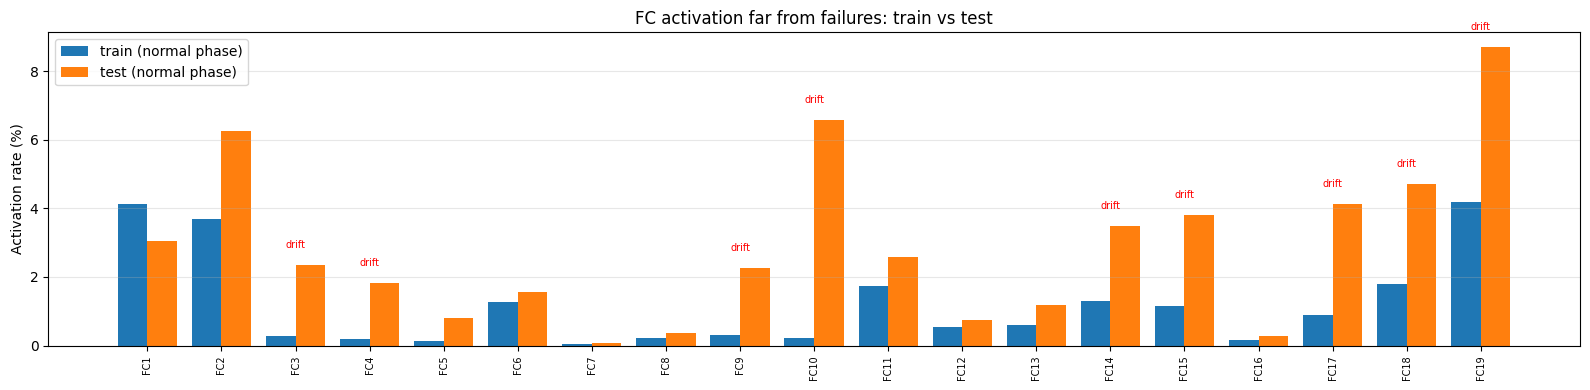

In [25]:
drift_rows = []
for fc in fc_ids:
    act = fc_act_all[fc]
    tr = act[(all_sup.split == 'train') & (all_sup.phase == 'normal')].mean()
    te = act[(all_sup.split == 'test') & (all_sup.phase == 'normal')].mean()
    ratio = te / tr if tr > 0 else np.inf
    drift_rows.append({'FC': f'FC{fc}', 'train_normal_rate_%': 100 * tr, 'test_normal_rate_%': 100 * te,
                       'test_train_ratio': ratio, 'drift_flag': bool(ratio >= 2 and te >= 0.01)})
fc_drift = pd.DataFrame(drift_rows)
print(fc_drift.round(2).to_string(index=False))
print(f'\nPossibly drift-driven FCs (test/train >= 2 and test rate >= 1%): '
      f'{", ".join(fc_drift.loc[fc_drift.drift_flag, "FC"]) or "none"}')

fig, ax = plt.subplots(figsize=(16, 4))
x = np.arange(len(fc_drift))
ax.bar(x - 0.2, fc_drift['train_normal_rate_%'], 0.4, label='train (normal phase)')
ax.bar(x + 0.2, fc_drift['test_normal_rate_%'], 0.4, label='test (normal phase)')
for i, flag in enumerate(fc_drift['drift_flag']):
    if flag:
        ax.text(i, max(fc_drift.loc[i, ['train_normal_rate_%', 'test_normal_rate_%']]) + 0.5, 'drift', ha='center', fontsize=7, color='red')
ax.set_xticks(x); ax.set_xticklabels(fc_drift['FC'], rotation=90, fontsize=7)
ax.set_ylabel('Activation rate (%)'); ax.set_title('FC activation far from failures: train vs test'); ax.legend(); ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Save Artifacts for NB05

In [26]:
# ── Save all artifacts for NB05 ──
artifact_dir = os.path.join(OUT_DIR, 'nb04_artifacts')
os.makedirs(artifact_dir, exist_ok=True)

# 1. all_sup (with is_anomalous, n_activated, split columns)
all_sup.to_parquet(os.path.join(artifact_dir, 'all_sup.parquet'))

# 2. Anomaly detection outputs
anom_activations.to_parquet(os.path.join(artifact_dir, 'anom_activations.parquet'))
anom_meta.to_parquet(os.path.join(artifact_dir, 'anom_meta.parquet'))
np.save(os.path.join(artifact_dir, 'anom_orig_idx.npy'), anom_orig_idx.values)

# 3. Feature clustering outputs
with open(os.path.join(artifact_dir, 'active_feats.json'), 'w') as f:
    json.dump(active_feats, f)

with open(os.path.join(artifact_dir, 'feature_cols.json'), 'w') as f:
    json.dump(feature_cols, f)

# Save heuristic_a feature clusters (FC1-FC19)
heuristic_a_serializable = {str(k): v for k, v in heuristic_a.items()}
with open(os.path.join(artifact_dir, 'heuristic_a.json'), 'w') as f:
    json.dump(heuristic_a_serializable, f, indent=2)

# 4. Canonical failure events and FC-level analysis tables
fail_events.to_parquet(os.path.join(artifact_dir, 'fail_events.parquet'))
fc_temporal.to_csv(os.path.join(artifact_dir, 'fc_temporal.csv'), index=False)
fc_variance.to_csv(os.path.join(artifact_dir, 'fc_variance.csv'), index=False)
fc_location.to_csv(os.path.join(artifact_dir, 'fc_location.csv'), index=False)
fc_drift.to_csv(os.path.join(artifact_dir, 'fc_drift.csv'), index=False)

# 5. Constants
with open(os.path.join(artifact_dir, 'constants.json'), 'w') as f:
    json.dump({
        'Z_THRESH': float(Z_THRESH),
        'MIN_ACTIVATED': int(MIN_ACTIVATED),
        'SPLIT_DATE': str(SPLIT_DATE),
        'HORIZON_S': int(HORIZON_S),
        'WINDOW_S': int(WINDOW_S),
    }, f)

print(f'Saved NB04 artifacts to {artifact_dir}/')
for fn in sorted(os.listdir(artifact_dir)):
    size = os.path.getsize(os.path.join(artifact_dir, fn))
    print(f'  {fn}: {size/1024:.0f} KB')

Saved NB04 artifacts to C:\Users\Emırhan\Desktop\MASTER THESIS\Kurtulus-thesis\outputs\nb04_artifacts/
  active_feats.json: 5 KB
  all_sup.parquet: 68902 KB
  anom_activations.parquet: 296 KB
  anom_meta.parquet: 129 KB
  anom_orig_idx.npy: 94 KB
  binary_vs_continuous_validation.png: 76 KB
  constants.json: 0 KB
  fail_events.parquet: 4 KB
  fc_drift.csv: 1 KB
  fc_location.csv: 1 KB
  fc_temporal.csv: 6 KB
  fc_variance.csv: 1 KB
  feature_cols.json: 10 KB
  heuristic_a.json: 6 KB
  heuristic_comparison.png: 165 KB


## Traceability: Pipeline Position

**NB01 > NB02 > NB03 > NB04 > NB05**

### What this notebook provides:
- Canonical failure-event table from the raw failure flag, shared with NB05
- Anomalous window detection (z-score > 3, >= 5 sensor features; context/asset features excluded)
- Binary activation profiles for all anomalous windows
- Feature clustering via Jaccard distance + average linkage (t=0.7) on the train-period anomalous windows → 19 feature clusters (FCs), 126 features
- Neutral sensor-location descriptors per FC (control chain, bogie, signal types)
- Heuristic comparison (Jaccard vs correlation) and binary vs continuous validation
- Temporal pattern analysis: phase enrichment (early / imminent / during), events hit, lead time per FC
- Failure-related day vs normal day contrast
- Volatility lead-up (real within-day variance, pre-onset ratio, Kendall τ)
- Drift checks (monthly anomaly rate, per-FC train vs test)

### What feeds into NB05:
- `heuristic_a.json`: the 19 feature clusters (FC1-FC19)
- `fail_events.parquet`: canonical failure events
- `anom_activations.parquet`, `anom_meta.parquet`, `anom_orig_idx.npy`, `all_sup.parquet`
- `fc_temporal.csv`, `fc_variance.csv`, `fc_location.csv`, `fc_drift.csv`
- `active_feats.json`, `feature_cols.json`, `constants.json`